# H2 — Conditional Creative Destruction

**Hypothesis:** Following a sudden natural disaster, the "creative destruction" rebound effect (where long-term MNE presence *surpasses* pre-shock levels) is predominantly observed in historically **un-prone** regions, where unexpected destruction forces modernization. Historically **prone** regions experience muted initial destruction and no modernization rebound.

**Design:** Event study — panel regressions of affiliate counts (ENT) on the contemporaneous sudden shock, interacted with the host country's dynamic historical disaster proneness. Running the model at horizons T=0 through T+5 traces the trajectory of the shock's effect over time.

**Main DV: ENT (number of affiliates)** — consistent with H1 and H3 which study the extensive and intensive margins of MNE presence. EMP (employment) is retained as a robustness check.

**Strategy A:** `industry == 'B-S_X_O'` (total manufacturing aggregate, maximum host-country coverage).  
**Fixed Effects:** Two-way FE — dyad (home × host × industry) and year.  
**Clustered SE:** By dyad.

---

| Version | Estimator | Sample | Dependent variable | Identifies |
|---------|-----------|--------|--------------------|------------|
| **V1** | Log-OLS (`PanelOLS`) | `ent > 0` at T=0 | `ln_ent` and `ln_ent_lead{k}` | Intensive margin: rebound of *established* affiliate presence |
| **V2** | PPML (`fepois`) | All obs (incl. zeros) | `ent` and `ent_lead{k}` in levels | Total effect: disruption + exit prevention / new entry |
| **V1b** | Log-OLS (robustness) | `emp > 0` at T=0 | `ln_emp` and `ln_emp_lead{k}` | Robustness: intensive margin rebound on employment |
| **V2b** | PPML (robustness) | All obs (incl. zeros) | `emp` and `emp_lead{k}` in levels | Robustness: total employment effect |

**Focal coefficients extracted for event study plots:**
- `sev_sudden_physical` — baseline shock effect at *average* historical exposure (due to mean-centering of the interaction term)
- `interaction_sudden_hist` — marginal change in the shock trajectory per +1 unit of log-density of historical exposure

**H2 prediction:** `interaction_sudden_hist` should be *negative* at T=0 (prone regions less disrupted) and remain flat/negative at longer horizons (no rebound), while the baseline `sev_sudden_physical` trajectory (un-prone regions) should recover or overshoot zero by T+3 to T+5.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS
import pyfixest as pf
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import HTML

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', font_scale=1.05)


## Step 1 — Load & Filter (Strategy A)

In [2]:
# Navigate to project root when running from notebooks/ subdirectory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

df_raw = pd.read_parquet('data/Silver/estimation_sample.parquet')

# Strategy A: total manufacturing aggregate — maximum host-country coverage, no GVC
df = df_raw[df_raw['industry'] == 'B-S_X_O'].copy()

# Dyad identifier: home × host × industry (used as panel entity for FE and clustering)
df['dyad_id'] = df['home_country'] + '_' + df['host_country'] + '_' + df['industry']

print(f'Strategy A rows : {len(df):,}')
print(f'Unique home      : {df["home_country"].nunique()}')
print(f'Unique host      : {df["host_country"].nunique()}')
print(f'Unique dyads     : {df["dyad_id"].nunique():,}')
print(f'Years            : {sorted(df["year"].unique())}')

Strategy A rows : 26,000
Unique home      : 29
Unique host      : 185
Unique dyads     : 2,472
Years            : [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


In [3]:
# ── Table export utilities (for copy-paste into Word) ──────────────────────────
# Every results table below is exported as .csv (Excel) and standalone .html.
# To get a clean paste into Word: open the .html file in a browser, select the
# table, Ctrl+C, then Ctrl+V into Word — the browser puts real HTML on the
# clipboard, so Word creates a native formatted table instead of space-padded
# text. A combined "all_tables.html" with every table is built in the last cell,
# with an abbreviations legend at the top (copy that legend into your thesis'
# list of abbreviations / table notes).
from pathlib import Path
import webbrowser

TABLES_DIR = Path("outputs/tables/h2")
TABLES_DIR.mkdir(parents=True, exist_ok=True)
_ALL_TABLES = []  # (title, DataFrame) — collected for the combined export

VAR_LABELS = {
    'sev_sudden_physical':     'D_sudden (sudden shock)',
    'interaction_sudden_hist': 'D_sudden x HistFreq_host',
    'sev_seasonal_physical':   'D_seasonal (placebo)',
    'ln_gdp_pc_host':          'ln GDPpc_host',
    'ln_gdp_pc_home':          'ln GDPpc_home',
    'ge_host':                 'GE_host',
    'ln_hist_cnt_pc_centered': 'ln HistFreq_host',
    'N':        'N',
    'R²':       'R²',
    'Pseudo R²':'Pseudo R²',
}

ABBR_DEFINITIONS = [
    ('D_sudden',                'Severity of sudden-onset physical disasters (host country), current year'),
    ('D_seasonal',              'Severity of seasonal physical disasters (host country), current year — placebo/control shock'),
    ('HistFreq_host',           'Historical disaster frequency per capita, host country, rolling 20y window (log, mean-centered)'),
    ('D_sudden x HistFreq_host','Interaction: sudden shock x historical disaster proneness — H2 moderator'),
    ('GDPpc_host / GDPpc_home', 'GDP per capita, constant 2015 USD, lagged one year (t-1)'),
    ('GE_host',                 'Government effectiveness, host country (WGI index)'),
    ('T=k / T+k',               'Event-study horizon: k years after the base-year shock'),
    ('OLS',                     'Log-linear panel OLS on ln(ENT) or ln(EMP), entity+year fixed effects, clustered SE by dyad — intensive margin (positive counts only)'),
    ('PPML',                    'Poisson pseudo-maximum-likelihood (fepois), entity+year fixed effects, clustered SE by dyad — total margin (zeros included)'),
    ('N',                       'Number of observations'),
    ('R² / Pseudo R²',          'R-squared (OLS) / Pseudo R-squared (PPML)'),
]

def apply_labels(df):
    out = df.copy()
    out.index = [VAR_LABELS.get(v, v) for v in out.index]
    out.index.name = df.index.name
    return out

def export_table(df, name, title=None):
    title = title or name
    csv_path  = TABLES_DIR / f"{name}.csv"
    html_path = TABLES_DIR / f"{name}.html"
    df.to_csv(csv_path)
    html_path.write_text(
        f"<html><head><meta charset='utf-8'><title>{title}</title></head>"
        f"<body><h2>{title}</h2>{df.to_html(border=1, na_rep='')}</body></html>",
        encoding="utf-8",
    )
    _ALL_TABLES.append((title, df))
    print(f"Exported '{name}': {csv_path.name}, {html_path.name}")

def build_master_html():
    legend_rows = "".join(
        f"<tr><td>{abbr}</td><td>{definition}</td></tr>"
        for abbr, definition in ABBR_DEFINITIONS
    )
    parts = ["<html><head><meta charset='utf-8'><title>H2 Regression tables</title></head><body>",
             "<p>Open this file in a browser, select each table, Ctrl+C, then "
             "Ctrl+V into Word to get a native formatted table.</p>",
             "<h2>Abbreviations</h2>",
             f"<table border='1'><tr><th>Abbreviation</th><th>Definition</th></tr>{legend_rows}</table>"]
    for title, tdf in _ALL_TABLES:
        parts.append(f"<h2>{title}</h2>")
        parts.append(tdf.to_html(border=1, na_rep=""))
    parts.append("</body></html>")
    out_path = TABLES_DIR / "all_tables.html"
    out_path.write_text("\n".join(parts), encoding="utf-8")
    print(f"Combined file: {out_path.resolve()}")
    return out_path

print(f"Tables will be exported to: {TABLES_DIR.resolve()}")


Tables will be exported to: <repo>\outputs\tables\h2


## Step 2 — Feature Engineering

### Historical Exposure Metric & Interaction Terms

**Why dynamic?**  
We use `hist_cnt_total_dynamic_host` (rolling 20-year event count, [year−20, year]) rather than the static 1988–2008 window. The static measure is time-invariant per host country and would be **fully absorbed by dyad fixed effects**, eliminating the main effect of historical exposure from the regression. The dynamic measure varies year-to-year, so after double-demeaning: (a) the main effect `ln_hist_cnt_pc_centered` remains identified, and (b) the interaction term has richer variation — both the shock *and* the proneness metric move. It also better captures firms' current risk perception: firms calibrate to *recent* experience, not a pre-panel baseline.

*Caveat:* A large shock at t−k enters both `sev_sudden_physical` at t−k and the rolling window at t. For our event-study horizons (k=1..5) this overlap is minor and transparent.

**Mean-centering rationale:**  
Centering `ln_hist_cnt_pc` before forming the interaction makes the main effect of `sev_sudden_physical` interpretable as the shock's impact on a dyad with *average* historical exposure, and reduces the variance-inflation factor between the main effect and the interaction term.

**GDP and institutional controls:** `ln_gdp_pc_host` (log GDP per capita at t−1, constant 2015 USD) and `ln_gdp_pc_home` and `ge_host` (WGI Government Effectiveness at t−1) are taken directly from the estimation sample parquet — the lags are pre-computed in the pipeline (scripts 08/09).

In [4]:
# Dynamic historical disaster density: rolling 20-year total event count, normalised by
# host population (in millions), then log-scaled for interpretability
df['ln_hist_cnt_pc'] = np.log1p(
    df['hist_cnt_total_dynamic_host'] / (df['pop_host'] / 1_000_000)
)

# Grand-mean centre — makes sev_sudden_physical the shock effect at average proneness
grand_mean = df['ln_hist_cnt_pc'].mean()
df['ln_hist_cnt_pc_centered'] = df['ln_hist_cnt_pc'] - grand_mean

# Key H2 moderator: does historical proneness dampen the creative-destruction rebound?
df['interaction_sudden_hist'] = df['sev_sudden_physical'] * df['ln_hist_cnt_pc_centered']

print(f'ln_hist_cnt_pc  — mean (pre-center): {grand_mean:.4f}')
print(f'ln_hist_cnt_pc  — range: [{df["ln_hist_cnt_pc"].min():.3f}, {df["ln_hist_cnt_pc"].max():.3f}]')
print(f'interaction_sudden_hist — non-zero rows: {(df["interaction_sudden_hist"] != 0).sum():,}')

ln_hist_cnt_pc  — mean (pre-center): 1.2390
ln_hist_cnt_pc  — range: [0.000, 4.926]
interaction_sudden_hist — non-zero rows: 3,793


## Step 3 — Forward Shifting (Leads T+1 to T+5)

We create leads of both `ent` / `ln_ent` (main DV) and `emp` / `ln_emp` (robustness DV).  
- Log transforms use `np.log(x)` — exact log, no `log1p` bias. Zeros replaced with `NaN` before taking the log (retained in PPML, excluded from OLS by the `> 0` filter).
- Leads via `groupby('dyad_id').shift(-k)` — no cross-dyad leakage.
- **Sample attrition at higher leads** is structural: dyads observed at T+5 are a shrinking subset as years 2015–2019 have fewer forward observations.

In [5]:
df.sort_values(['dyad_id', 'year'], inplace=True)

# Main DV: ENT (affiliate count)
df['ln_ent'] = np.log(df['ent'].replace(0, np.nan))

for k in range(1, 6):
    df[f'ent_lead{k}']    = df.groupby('dyad_id')['ent'].shift(-k)
    df[f'ln_ent_lead{k}'] = df.groupby('dyad_id')['ln_ent'].shift(-k)

# Robustness DV: EMP (employment)
df['ln_emp'] = np.log(df['emp'].replace(0, np.nan))

for k in range(1, 6):
    df[f'emp_lead{k}']    = df.groupby('dyad_id')['emp'].shift(-k)
    df[f'ln_emp_lead{k}'] = df.groupby('dyad_id')['ln_emp'].shift(-k)

# Attrition summary
print('Horizon | ent non-null | ln_ent non-null | emp non-null | ln_emp non-null')
print(f'T=0     | {df["ent"].notna().sum():>12,} | {df["ln_ent"].notna().sum():>15,} | {df["emp"].notna().sum():>12,} | {df["ln_emp"].notna().sum():>15,}')
for k in range(1, 6):
    print(f'T+{k}     | {df[f"ent_lead{k}"].notna().sum():>12,} | {df[f"ln_ent_lead{k}"].notna().sum():>15,} | {df[f"emp_lead{k}"].notna().sum():>12,} | {df[f"ln_emp_lead{k}"].notna().sum():>15,}')

Horizon | ent non-null | ln_ent non-null | emp non-null | ln_emp non-null
T=0     |       25,798 |          21,744 |       19,910 |          15,755
T+1     |       23,343 |          19,837 |       17,934 |          14,335
T+2     |       20,906 |          17,878 |       16,031 |          12,920
T+3     |       18,496 |          15,915 |       14,121 |          11,468
T+4     |       16,110 |          13,931 |       12,266 |          10,023
T+5     |       13,770 |          11,968 |       10,473 |           8,613


In [6]:
# Guard: log(ent) must never contain ±inf (replace(0, nan) above prevents log(0) = -inf)
assert not df['ln_ent'].isin([np.inf, -np.inf]).any(), \
    'ln_ent contains ±inf — check ent values'
assert not df['ln_emp'].isin([np.inf, -np.inf]).any(), \
    'ln_emp contains ±inf — check emp values'

# Guard: sev_sudden_physical must have positive values for identification
assert df['sev_sudden_physical'].max() > 0, \
    'sev_sudden_physical is all-zero — check data filter'

print('Assertions passed.')
print(f'  sev_sudden_physical max : {df["sev_sudden_physical"].max():.4f}')
print(f'  sev_sudden_physical > 0 : {(df["sev_sudden_physical"] > 0).sum():,} rows')
print(f'  ent > 0 rows            : {(df["ent"] > 0).sum():,}')
print(f'  emp > 0 rows            : {(df["emp"] > 0).sum():,}')

Assertions passed.
  sev_sudden_physical max : 0.3202
  sev_sudden_physical > 0 : 3,793 rows
  ent > 0 rows            : 21,744
  emp > 0 rows            : 15,755


## Step 4 — Define Regressors

Seven regressors. The main effect `ln_hist_cnt_pc_centered` **must** be included whenever the interaction is present — omitting it would conflate the interaction coefficient with the uncontrolled level effect of historical proneness.

**H2 sign predictions:**
- `sev_sudden_physical` : expected negative at T=0 (destruction), becoming **positive** at T+3/T+5 (creative-destruction rebound for historically un-prone regions at average exposure)
- `interaction_sudden_hist` : expected **positive** at T=0 (prone regions are better prepared → less initial disruption → higher effect for them), then **negative** at T+3/T+5 (prone regions forgo the rebound — no forced modernization — so the positive baseline effect is cancelled for them)

In [7]:
CONTROLS = [
    'sev_sudden_physical',       # direct shock effect (at average historical exposure)
    'interaction_sudden_hist',   # H2 moderator: shock × log historical disaster density
    'sev_seasonal_physical',     # direct seasonal shock (control / placebo)
    'ln_gdp_pc_host',            # host log GDP per capita at t-1 (pre-computed in pipeline)
    'ln_gdp_pc_home',            # home log GDP per capita at t-1 (pre-computed in pipeline)
    'ge_host',                   # WGI Government Effectiveness — host institutional quality at t-1
    'ln_hist_cnt_pc_centered',   # main effect of historical proneness (required with interaction)
]

print('Regressor list confirmed:', CONTROLS)

Regressor list confirmed: ['sev_sudden_physical', 'interaction_sudden_hist', 'sev_seasonal_physical', 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host', 'ln_hist_cnt_pc_centered']


## Step 5 — V1: Log-OLS Regressions — ENT (Intensive Margin)

**Sample filter:** `ent > 0` at the base observation.  
Rationale: OLS on `ln_ent` requires a positive dependent variable. This restricts inference to *established* affiliate relationships — dyads where MNE affiliates were actively present. We are asking: conditional on being present, does a sudden disaster reduce and then rebound affiliate counts?

For each horizon k ∈ {0, 1, 2, 3, 4, 5}, the dependent variable is `ln_ent` (k=0) or `ln_ent_lead{k}` (k≥1). Listwise deletion on the DV and all controls is applied per horizon — we do **not** restrict the sample to a balanced subset across horizons.

In [8]:
# Restrict to dyad-years where the base-period affiliate count is positive
df_ols_base = df[df['ent'] > 0].copy()

print(f'Base OLS sample (ent > 0): {len(df_ols_base):,} obs  '
      f'| {df_ols_base["dyad_id"].nunique():,} dyads\n')

ols_results = {}  # horizon k -> fitted PanelOLS result

for k in range(6):
    dv = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_ols_base[cols].dropna().copy()

    df_panel = df_est.set_index(['dyad_id', 'year'])
    y = df_panel[dv]
    X = df_panel[CONTROLS]

    mod = PanelOLS(
        dependent=y,
        exog=X,
        entity_effects=True,
        time_effects=True,
    )
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    ols_results[k] = res

    b_s = res.params['sev_sudden_physical']
    b_i = res.params['interaction_sudden_hist']
    print(
        f'T+{k}  N={int(res.nobs):>7,}  dyads={int(res.entity_info["total"]):>5,}  '
        f'β_sudden={b_s:+.4f}  β_interact={b_i:+.4f}'
    )

Base OLS sample (ent > 0): 21,744 obs  | 2,472 dyads



T+0  N= 21,744  dyads=2,472  β_sudden=+0.3528  β_interact=-0.1746


T+1  N= 18,983  dyads=2,321  β_sudden=+0.1702  β_interact=-0.2962


T+2  N= 16,680  dyads=2,197  β_sudden=-0.3071  β_interact=-1.1317
T+3  N= 14,581  dyads=2,100  β_sudden=-0.5231  β_interact=-0.4686


T+4  N= 12,573  dyads=2,025  β_sudden=-0.2245  β_interact=+0.2986
T+5  N= 10,652  dyads=1,952  β_sudden=-0.6681  β_interact=+0.0492


In [9]:
# Extract focal coefficients and 95% CIs for the event study plot (ENT)
def stars(p):
    return '***' if p < 0.01 else ('**' if p < 0.05 else ('*' if p < 0.1 else ''))

rows = []
for k in range(6):
    res = ols_results[k]
    rows.append({
        'horizon':       k,
        'n_obs':         int(res.nobs),
        'n_dyads':       int(res.entity_info['total']),
        'sudden_coef':   res.params['sev_sudden_physical'],
        'sudden_se':     res.std_errors['sev_sudden_physical'],
        'sudden_p':      res.pvalues['sev_sudden_physical'],
        'interact_coef': res.params['interaction_sudden_hist'],
        'interact_se':   res.std_errors['interaction_sudden_hist'],
        'interact_p':    res.pvalues['interaction_sudden_hist'],
    })

ols_coefs = pd.DataFrame(rows)
ols_coefs['sudden_lo95']   = ols_coefs['sudden_coef']   - 1.96 * ols_coefs['sudden_se']
ols_coefs['sudden_hi95']   = ols_coefs['sudden_coef']   + 1.96 * ols_coefs['sudden_se']
ols_coefs['interact_lo95'] = ols_coefs['interact_coef'] - 1.96 * ols_coefs['interact_se']
ols_coefs['interact_hi95'] = ols_coefs['interact_coef'] + 1.96 * ols_coefs['interact_se']
ols_coefs['sudden_sig']    = ols_coefs['sudden_p'].apply(stars)
ols_coefs['interact_sig']  = ols_coefs['interact_p'].apply(stars)

display_cols = [
    'horizon', 'n_obs', 'n_dyads',
    'sudden_coef', 'sudden_p', 'sudden_sig',
    'interact_coef', 'interact_p', 'interact_sig',
]
display(ols_coefs[display_cols].round(4))

,horizon,n_obs,n_dyads,sudden_coef,sudden_p,sudden_sig,interact_coef,interact_p,interact_sig
0,0,21744,2472,0.3528,0.3013,,-0.1746,0.8898,
1,1,18983,2321,0.1702,0.6503,,-0.2962,0.7758,
2,2,16680,2197,-0.3071,0.3905,,-1.1317,0.1801,
3,3,14581,2100,-0.5231,0.4038,,-0.4686,0.7128,
4,4,12573,2025,-0.2245,0.5977,,0.2986,0.8234,
5,5,10652,1952,-0.6681,0.0954,*,0.0492,0.9567,


### V1 — Full Coefficient Table (all regressors, ENT)

All seven regressors shown as rows, horizons T=0 to T+5 as columns. Each cell shows the coefficient (with significance stars) on the first line and the p-value in parentheses on the second line. The bottom rows report N, the number of unique disasters entering the estimation sample (host-country × year pairs with a sudden / seasonal shock, counted separately), and R².


In [10]:
def _sample_stats(source_df, dv, controls, filter_dv):
    """N and unique-disaster counts (host_country x year pairs) for one horizon's estimation sample."""
    cols = ['host_country', 'year', dv] + controls
    d = source_df[[c for c in cols if c in source_df.columns]]
    if filter_dv:
        d = d[d[dv] >= 0]
    d = d.dropna(subset=[dv] + controls)
    n_sudden   = d.loc[d['sev_sudden_physical']   > 0, ['host_country', 'year']].drop_duplicates().shape[0]
    n_seasonal = d.loc[d['sev_seasonal_physical'] > 0, ['host_country', 'year']].drop_duplicates().shape[0]
    return len(d), n_sudden, n_seasonal


def _coef_cell_df(coef_df, p_df):
    """Coefficient (+ stars) on line 1, p-value in parentheses on line 2."""
    out = pd.DataFrame(index=coef_df.index, columns=coef_df.columns, dtype=object)
    for r in coef_df.index:
        for c in coef_df.columns:
            b, p = coef_df.loc[r, c], p_df.loc[r, c]
            out.loc[r, c] = f'{b:+.4f}{stars(p)}<br>({p:.3f})'
    return out


def _render_full_table(coef_df, p_df, n_row, sudden_row, seasonal_row, r2_row, r2_label, title):
    cell_df = _coef_cell_df(coef_df, p_df)
    extra_df = pd.DataFrame({
        'N':                            n_row,
        'Disasters uniques — sudden':   sudden_row,
        'Disasters uniques — seasonal': seasonal_row,
        r2_label:                       r2_row,
    }).T[coef_df.columns]

    combined = pd.concat([cell_df, extra_df])
    combined.index.name = 'Regressor'
    combined.columns.name = 'Horizon'

    print(f'\n{title}')
    display(HTML(combined.to_html(escape=False)))
    return combined


def ols_full_table(results_dict, controls, source_df, dv_base, title):
    """Full coefficient table (all regressors x horizons) for a PanelOLS results dict."""
    coef_rows, p_rows = {}, {}
    n_row, sudden_row, seasonal_row, r2_row = {}, {}, {}, {}
    for k, res in results_dict.items():
        h = 'T=0' if k == 0 else f'T+{k}'
        coef_rows[h] = {v: res.params[v]  for v in controls}
        p_rows[h]    = {v: res.pvalues[v] for v in controls}

        dv = dv_base if k == 0 else f'{dv_base}_lead{k}'
        n, n_sud, n_sea = _sample_stats(source_df, dv, controls, filter_dv=False)
        n_row[h], sudden_row[h], seasonal_row[h] = f'{n:,}', f'{n_sud:,}', f'{n_sea:,}'
        r2_row[h] = f'{res.rsquared:.3f}'

    coef_df = pd.DataFrame(coef_rows)[list(coef_rows.keys())]
    p_df    = pd.DataFrame(p_rows)[coef_df.columns]
    return _render_full_table(coef_df, p_df, n_row, sudden_row, seasonal_row, r2_row, 'R²', title)


ols_full_combined = ols_full_table(
    ols_results, CONTROLS, df_ols_base, 'ln_ent',
    'V1 — OLS (ln_ent) — All coefficients'
)
export_table(apply_labels(ols_full_combined), "h2_v1_ols_full_ent", "V1 — OLS full coefficient table, all regressors x horizons (ENT)")



V1 — OLS (ln_ent) — All coefficients


Horizon,T=0,T+1,T+2,T+3,T+4,T+5
Regressor,,,,,,
sev_sudden_physical,+0.3528(0.301),+0.1702(0.650),-0.3071(0.390),-0.5231(0.404),-0.2245(0.598),-0.6681*(0.095)
interaction_sudden_hist,-0.1746(0.890),-0.2962(0.776),-1.1317(0.180),-0.4686(0.713),+0.2986(0.823),+0.0492(0.957)
sev_seasonal_physical,-0.0332(0.768),+0.0442(0.686),+0.0883(0.521),+0.0640(0.636),-0.1129(0.487),-0.0365(0.808)
ln_gdp_pc_host,+0.5125***(0.000),+0.4550***(0.000),+0.3700***(0.000),+0.2286***(0.005),+0.1724**(0.045),+0.0771(0.378)
ln_gdp_pc_home,+0.9747***(0.000),+0.8723***(0.000),+0.6063***(0.000),+0.4493***(0.002),+0.2286(0.134),+0.0733(0.645)
ge_host,-0.0149(0.649),+0.0057(0.866),+0.0333(0.325),+0.0759**(0.030),+0.0615*(0.085),+0.0449(0.352)
ln_hist_cnt_pc_centered,-0.0466(0.347),-0.0499(0.325),-0.0248(0.640),+0.0083(0.875),+0.0256(0.628),+0.0489(0.357)
N,"21,744","18,983","16,680","14,581","12,573","10,652"
Disasters uniques — sudden,281,248,226,199,174,155


Exported 'h2_v1_ols_full_ent': h2_v1_ols_full_ent.csv, h2_v1_ols_full_ent.html


### V1 Results — Interpretation (OLS, Intensive Margin — ENT)

**Baseline shock trajectory (`sev_sudden_physical`):**

Contrary to H2's prediction of an initial negative shock, the coefficient is slightly *positive* at T=0 (+0.353, p = 0.30) and T+1 (+0.170, p = 0.65), though never statistically significant. This early positive sign is surprising and may reflect organizational inertia: affiliate counts (ENT) are structural variables that firms do not adjust immediately after a disaster — they keep the legal entity open while assessing damage and waiting for insurance settlements. It may also partly capture new affiliates created specifically for reconstruction activities.

The trajectory then deteriorates steadily: the coefficient turns negative at T+2 (−0.307), worsens slightly at T+3 (−0.523) and T+4 (−0.224), and reaches its most negative value at **T+5: β = −0.668 (p = 0.095)**. This is the only marginally significant estimate in the OLS event study. The pattern is best described as a **delayed exit** mechanism: rather than immediately closing affiliates after a sudden disaster, MNEs maintain organizational presence for 3–4 years while absorbing losses, then progressively reduce or exit in year 5. Crucially, the coefficient never becomes positive — there is no creative-destruction overshoot at any horizon.

This ENT trajectory is distinct from the EMP robustness results (see V1b below), where the peak disruption occurs at **T+3** and employment partially recovers by T+5. The divergence between ENT (affiliate count) and EMP (employment) is economically coherent: firms first cut headcount at T+3 while maintaining the affiliate's legal existence, then formally exit around year 5.

**H2 prediction on the baseline:** *Not supported.* H2 requires β_sudden to become positive by T+3–T+5, reflecting creative-destruction overshoot. The ENT coefficient stays negative throughout, consistent with persistent disruption rather than renewal.

**Interaction modifier (`interaction_sudden_hist`):**

The interaction is economically and statistically negligible at all horizons. Coefficients range from −1.132 (T+2, p = 0.18) to +0.299 (T+4, p = 0.82) with no discernible pattern and no p-value below 0.18. Directionally, the coefficient is negative from T=0 to T+3 (opposite to the H2 prediction of a positive sign at T=0) and weakly positive at T+4–T+5 (opposite to the H2 prediction of a negative sign at long horizons). There is no evidence whatsoever that historical disaster proneness moderates the affiliate count trajectory following a sudden shock.

**Full-table controls:**

The economic controls perform as expected. `ln_gdp_pc_host` is strongly positive and significant at T=0 through T+4 (β ≈ 0.51–0.17, p < 0.05), indicating that wealthier host countries retain more foreign affiliates after shocks — consistent with better reconstruction capacity and institutional resilience. `ln_gdp_pc_home` is similarly positive and highly significant at T=0 through T+3, reflecting the size of the home economy as a structural driver of outward FDI. `ge_host` (Government Effectiveness) is marginally significant at T+3 (β = 0.076, p < 0.05) and T+4 (β = 0.062, p < 0.10), suggesting that better-governed host countries provide a longer-run buffer for MNE presence. The seasonal placebo (`sev_seasonal_physical`) is uniformly small and insignificant across all horizons — a reassuring falsification result consistent with the theoretical boundary condition that anticipated shocks do not trigger modernization investment.

## Step 6 — V2: PPML Regressions — ENT (Total Margin)

**Sample:** Full Strategy A panel, including `ent = 0` observations (except rare negative values, excluded).  
PPML identifies the *total* effect — disruption of existing affiliates **plus** disasters that deter new entry or accelerate exit. It is consistent under multiplicative heteroskedasticity (Santos Silva & Tenreyro, 2006). The `pyfixest.fepois()` implementation is equivalent to Stata's `ppmlhdfe`.

**Inference:** `vcov={'CRV1': 'dyad_id'}` — cluster-robust variance by dyad, symmetric with V1.

In [11]:
ppml_results = {}  # horizon k -> fitted pyfixest fepois result

rhs = ' + '.join(CONTROLS)

for k in range(6):
    dv = 'ent' if k == 0 else f'ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS

    # Keep ent >= 0 (exclude negative accounting corrections), retain zeros for PPML
    df_est = (
        df[df[dv] >= 0][cols]
        .dropna(subset=CONTROLS + [dv])
        .copy()
    )

    fml = f'{dv} ~ {rhs} | dyad_id + year'

    fit = pf.fepois(
        fml,
        data=df_est,
        vcov={'CRV1': 'dyad_id'},
    )
    ppml_results[k] = fit

    b_s = float(fit.coef()['sev_sudden_physical'])
    b_i = float(fit.coef()['interaction_sudden_hist'])
    print(
        f'T+{k}  N={len(df_est):>7,}  '
        f'β_sudden={b_s:+.4f}  β_interact={b_i:+.4f}'
    )

T+0  N= 25,798  β_sudden=-0.3315  β_interact=-0.4974


T+1  N= 23,343  β_sudden=-0.3404  β_interact=-1.1506


T+2  N= 20,906  β_sudden=-0.0349  β_interact=-2.2771
T+3  N= 18,496  β_sudden=-0.5711  β_interact=+0.4977


T+4  N= 16,110  β_sudden=-0.3773  β_interact=+1.5843
T+5  N= 13,770  β_sudden=-0.7654  β_interact=+0.9764


In [12]:
# Extract focal coefficients and 95% CIs from pyfixest confint() (ENT)
ppml_rows = []
for k in range(6):
    fit = ppml_results[k]
    ci  = fit.confint()
    ppml_rows.append({
        'horizon':        k,
        'sudden_coef':    float(fit.coef()['sev_sudden_physical']),
        'sudden_lo95':    float(ci.loc['sev_sudden_physical',   '2.5%']),
        'sudden_hi95':    float(ci.loc['sev_sudden_physical',   '97.5%']),
        'sudden_p':       float(fit.pvalue()['sev_sudden_physical']),
        'interact_coef':  float(fit.coef()['interaction_sudden_hist']),
        'interact_lo95':  float(ci.loc['interaction_sudden_hist', '2.5%']),
        'interact_hi95':  float(ci.loc['interaction_sudden_hist', '97.5%']),
        'interact_p':     float(fit.pvalue()['interaction_sudden_hist']),
    })

ppml_coefs = pd.DataFrame(ppml_rows)
ppml_coefs['sudden_se']    = (ppml_coefs['sudden_hi95']   - ppml_coefs['sudden_lo95'])   / (2 * 1.96)
ppml_coefs['interact_se']  = (ppml_coefs['interact_hi95'] - ppml_coefs['interact_lo95']) / (2 * 1.96)
ppml_coefs['sudden_sig']   = ppml_coefs['sudden_p'].apply(stars)
ppml_coefs['interact_sig'] = ppml_coefs['interact_p'].apply(stars)

display_cols = [
    'horizon',
    'sudden_coef', 'sudden_p', 'sudden_sig',
    'interact_coef', 'interact_p', 'interact_sig',
]
display(ppml_coefs[display_cols].round(4))

,horizon,sudden_coef,sudden_p,sudden_sig,interact_coef,interact_p,interact_sig
0,0,-0.3315,0.4555,,-0.4974,0.6987,
1,1,-0.3404,0.4211,,-1.1506,0.4672,
2,2,-0.0349,0.9345,,-2.2771,0.1905,
3,3,-0.5711,0.1572,,0.4977,0.7097,
4,4,-0.3773,0.3815,,1.5843,0.2284,
5,5,-0.7654,0.0421,**,0.9764,0.4158,


### V2 — Full Coefficient Table (all regressors, ENT)

All seven regressors shown as rows, horizons T=0 to T+5 as columns. Each cell shows the coefficient (with significance stars) on the first line and the p-value in parentheses on the second line. The bottom rows report N, the number of unique disasters entering the estimation sample (host-country × year pairs with a sudden / seasonal shock, counted separately), and pseudo R².


In [13]:
def ppml_full_table(results_dict, controls, source_df, dv_base, title):
    """Full coefficient table (all regressors x horizons) for a pyfixest fepois results dict."""
    coef_rows, p_rows = {}, {}
    n_row, sudden_row, seasonal_row, r2_row = {}, {}, {}, {}
    for k, fit in results_dict.items():
        h = 'T=0' if k == 0 else f'T+{k}'
        coef_rows[h] = {v: float(fit.coef()[v])   for v in controls}
        p_rows[h]    = {v: float(fit.pvalue()[v]) for v in controls}

        dv = dv_base if k == 0 else f'{dv_base}_lead{k}'
        n, n_sud, n_sea = _sample_stats(source_df, dv, controls, filter_dv=True)
        n_row[h], sudden_row[h], seasonal_row[h] = f'{n:,}', f'{n_sud:,}', f'{n_sea:,}'
        r2_row[h] = f'{fit._pseudo_r2:.3f}'

    coef_df = pd.DataFrame(coef_rows)[list(coef_rows.keys())]
    p_df    = pd.DataFrame(p_rows)[coef_df.columns]
    return _render_full_table(coef_df, p_df, n_row, sudden_row, seasonal_row, r2_row, 'Pseudo R²', title)


ppml_full_combined = ppml_full_table(
    ppml_results, CONTROLS, df, 'ent',
    'V2 — PPML (ent) — All coefficients'
)
export_table(apply_labels(ppml_full_combined), "h2_v2_ppml_full_ent", "V2 — PPML full coefficient table, all regressors x horizons (ENT)")



V2 — PPML (ent) — All coefficients


Horizon,T=0,T+1,T+2,T+3,T+4,T+5
Regressor,,,,,,
sev_sudden_physical,-0.3315(0.455),-0.3404(0.421),-0.0349(0.935),-0.5711(0.157),-0.3773(0.382),-0.7654**(0.042)
interaction_sudden_hist,-0.4974(0.699),-1.1506(0.467),-2.2771(0.190),+0.4977(0.710),+1.5843(0.228),+0.9764(0.416)
sev_seasonal_physical,+0.0548(0.478),+0.1490(0.137),+0.2117*(0.066),+0.1737(0.269),+0.1526(0.499),-0.0489(0.762)
ln_gdp_pc_host,+0.3374***(0.005),+0.2667**(0.024),+0.1854(0.123),-0.0002(0.998),-0.1210(0.231),-0.2308***(0.010)
ln_gdp_pc_home,+0.9372***(0.000),+0.8365***(0.000),+0.7213***(0.000),+0.3981**(0.032),+0.0898(0.640),-0.1611(0.399)
ge_host,-0.0148(0.708),+0.0112(0.777),+0.0165(0.693),+0.0207(0.665),-0.0136(0.791),-0.0147(0.824)
ln_hist_cnt_pc_centered,-0.0503(0.463),-0.0739(0.226),-0.0637(0.262),-0.0484(0.369),-0.0019(0.972),-0.0070(0.901)
N,"25,798","23,343","20,906","18,496","16,110","13,770"
Disasters uniques — sudden,289,259,237,211,188,168


Exported 'h2_v2_ppml_full_ent': h2_v2_ppml_full_ent.csv, h2_v2_ppml_full_ent.html


### V2 Results — Interpretation (PPML, Total Margin — ENT)

**Baseline shock trajectory (`sev_sudden_physical`):**

Unlike the OLS estimator, which returned a slightly positive coefficient at T=0 (possibly driven by the restriction to established affiliates), PPML finds a consistently negative trajectory from T=0 through T+5. Coefficients range from −0.033 (T+2, p = 0.93) to −0.765 (T+5, p = 0.042). The **T+5 estimate is the only statistically significant result** across all six PPML horizons: a sudden disaster reduces expected affiliate counts by approximately 54% (semi-elasticity: exp(−0.765) − 1 ≈ −0.54) five years after the event, relative to comparable non-shocked dyads.

This confirms and sharpens the OLS result: the main impact of sudden disasters on foreign affiliate presence is not immediate but delayed, materialising fully only at a 5-year horizon. The PPML figure is particularly valuable here because it incorporates zero-affiliate dyads, capturing the exit margin (affiliates closing entirely) rather than just headcount reduction within surviving affiliates.

The absence of a significant effect at T=0 through T+4 in PPML is consistent with two complementary mechanisms: (1) firms maintain their affiliates in the short run while waiting out the shock (organizational stickiness), and (2) new entrants or reconstruction-linked affiliates partly offset the closures in the first few years, with the net effect only becoming visible at T+5.

**H2 prediction on the baseline:** *Not supported.* No horizon shows a positive β_sudden, ruling out a creative-destruction overshoot at any event-study horizon up to 5 years.

**Interaction modifier (`interaction_sudden_hist`):**

The interaction displays an interesting directional pattern, even if it never reaches conventional significance. At T=0 through T+2, the coefficients are negative and growing in magnitude (−0.50, −1.15, −2.28), peaking at T+2 (p = 0.19). This means prone regions (high historical exposure, positive ln_hist_cnt_pc_centered) experience a *more* negative affiliate count effect at short horizons than un-prone regions — the opposite of H2's prediction that prone regions should be less disrupted.

At T+3 through T+5, the interaction switches to positive (0.50, 1.58, 0.98), which would directionally suggest prone regions fare better at long horizons, but again none are statistically significant and the magnitudes are insufficient to offset the overall negative β_sudden trend.

Overall, the interaction pattern in PPML does not trace the sign trajectory predicted by H2 (positive then negative), and at no horizon does it attain statistical power. The creative-destruction mechanism — if it operates at all — is not mediated by historical disaster proneness in this aggregate sample.

**Full-table controls:**

`ln_gdp_pc_host` is robustly positive at T=0 (β = 0.337, p < 0.001) and T+1 (β = 0.267, p < 0.01), consistent with wealthier host countries sustaining affiliate presence. The coefficient attenuates and turns slightly negative at T+4 and T+5, suggesting that GDP levels offer diminishing protection against eventual MNE exit following large disasters. `ln_gdp_pc_home` is very strongly positive at T=0 through T+3 (β ≈ 0.93–0.40), confirming structural home-country size effects. The seasonal placebo is mostly insignificant (one marginal exception at T+2: β = 0.21, p = 0.08), passing the falsification test.

---

## Step 6b — Robustness: V1b Log-OLS & V2b PPML on EMP

Same specification as V1/V2, replacing ENT with EMP as the dependent variable. EMP and ENT are closely linked (more affiliates → more employees) but measure different margins: ENT captures the count of organizational units while EMP captures the total workforce. Consistency between ENT and EMP results strengthens the credibility of the findings.

In [14]:
# V1b — OLS on ln_emp (robustness)
df_ols_rob = df[df['emp'] > 0].copy()

print(f'Robustness OLS sample (emp > 0): {len(df_ols_rob):,} obs  '
      f'| {df_ols_rob["dyad_id"].nunique():,} dyads\n')

ols_rob_results = {}

for k in range(6):
    dv = 'ln_emp' if k == 0 else f'ln_emp_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_ols_rob[cols].dropna().copy()

    df_panel = df_est.set_index(['dyad_id', 'year'])
    y = df_panel[dv]
    X = df_panel[CONTROLS]

    mod = PanelOLS(dependent=y, exog=X, entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    ols_rob_results[k] = res

    b_s = res.params['sev_sudden_physical']
    b_i = res.params['interaction_sudden_hist']
    print(
        f'T+{k}  N={int(res.nobs):>7,}  dyads={int(res.entity_info["total"]):>5,}  '
        f'β_sudden={b_s:+.4f}  β_interact={b_i:+.4f}'
    )

Robustness OLS sample (emp > 0): 15,755 obs  | 1,902 dyads



T+0  N= 15,755  dyads=1,902  β_sudden=-0.9897  β_interact=+2.3762


T+1  N= 13,363  dyads=1,733  β_sudden=-0.6728  β_interact=+1.4284
T+2  N= 11,698  dyads=1,636  β_sudden=-0.4691  β_interact=-1.7099


T+3  N= 10,177  dyads=1,552  β_sudden=-1.7330  β_interact=+1.9103
T+4  N=  8,756  dyads=1,482  β_sudden=+0.1979  β_interact=-1.5784


T+5  N=  7,437  dyads=1,421  β_sudden=+0.7034  β_interact=-1.7649


In [15]:
# Extract focal coefficients — V1b (EMP)
rob_ols_rows = []
for k in range(6):
    res = ols_rob_results[k]
    rob_ols_rows.append({
        'horizon':       k,
        'n_obs':         int(res.nobs),
        'n_dyads':       int(res.entity_info['total']),
        'sudden_coef':   res.params['sev_sudden_physical'],
        'sudden_se':     res.std_errors['sev_sudden_physical'],
        'sudden_p':      res.pvalues['sev_sudden_physical'],
        'interact_coef': res.params['interaction_sudden_hist'],
        'interact_se':   res.std_errors['interaction_sudden_hist'],
        'interact_p':    res.pvalues['interaction_sudden_hist'],
    })

ols_rob_coefs = pd.DataFrame(rob_ols_rows)
ols_rob_coefs['sudden_lo95']   = ols_rob_coefs['sudden_coef']   - 1.96 * ols_rob_coefs['sudden_se']
ols_rob_coefs['sudden_hi95']   = ols_rob_coefs['sudden_coef']   + 1.96 * ols_rob_coefs['sudden_se']
ols_rob_coefs['interact_lo95'] = ols_rob_coefs['interact_coef'] - 1.96 * ols_rob_coefs['interact_se']
ols_rob_coefs['interact_hi95'] = ols_rob_coefs['interact_coef'] + 1.96 * ols_rob_coefs['interact_se']
ols_rob_coefs['sudden_sig']    = ols_rob_coefs['sudden_p'].apply(stars)
ols_rob_coefs['interact_sig']  = ols_rob_coefs['interact_p'].apply(stars)

# Full coefficient table — V1b
ols_rob_full_combined = ols_full_table(
    ols_rob_results, CONTROLS, df_ols_rob, 'ln_emp',
    'V1b — OLS (ln_emp) — All coefficients'
)



V1b — OLS (ln_emp) — All coefficients


Horizon,T=0,T+1,T+2,T+3,T+4,T+5
Regressor,,,,,,
sev_sudden_physical,-0.9897(0.352),-0.6728(0.547),-0.4691(0.476),-1.7330**(0.036),+0.1979(0.771),+0.7034(0.287)
interaction_sudden_hist,+2.3762(0.407),+1.4284(0.709),-1.7099(0.485),+1.9103(0.515),-1.5784(0.529),-1.7649(0.394)
sev_seasonal_physical,-0.2360(0.494),-0.0312(0.900),-0.1476(0.537),+0.2292(0.435),+0.1625(0.554),-0.0235(0.937)
ln_gdp_pc_host,+0.8848***(0.000),+0.6007***(0.000),+0.3399**(0.036),+0.0393(0.823),-0.0576(0.746),-0.1769(0.310)
ln_gdp_pc_home,+2.0003***(0.000),+1.8250***(0.000),+1.7075***(0.000),+1.6340***(0.000),+1.6772***(0.000),+1.3292***(0.000)
ge_host,-0.1060(0.153),-0.0857(0.210),-0.0361(0.580),-0.0299(0.656),-0.0658(0.356),-0.0931(0.336)
ln_hist_cnt_pc_centered,+0.0495(0.675),+0.0744(0.547),+0.0807(0.507),+0.1568(0.179),+0.2359*(0.096),+0.2191*(0.064)
N,"15,755","13,363","11,698","10,177","8,756","7,437"
Disasters uniques — sudden,258,229,205,181,162,140


In [16]:
# V2b — PPML on emp (robustness)
ppml_rob_results = {}
rhs = ' + '.join(CONTROLS)

for k in range(6):
    dv = 'emp' if k == 0 else f'emp_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS

    df_est = (
        df[df[dv] >= 0][cols]
        .dropna(subset=CONTROLS + [dv])
        .copy()
    )

    fml = f'{dv} ~ {rhs} | dyad_id + year'
    fit = pf.fepois(fml, data=df_est, vcov={'CRV1': 'dyad_id'})
    ppml_rob_results[k] = fit

    b_s = float(fit.coef()['sev_sudden_physical'])
    b_i = float(fit.coef()['interaction_sudden_hist'])
    print(f'T+{k}  N={len(df_est):>7,}  β_sudden={b_s:+.4f}  β_interact={b_i:+.4f}')

T+0  N= 19,910  β_sudden=-0.6100  β_interact=-1.7992
T+1  N= 17,934  β_sudden=+0.0414  β_interact=-1.1845


T+2  N= 16,031  β_sudden=-0.3679  β_interact=-1.1211
T+3  N= 14,121  β_sudden=-0.9698  β_interact=+1.1198


T+4  N= 12,266  β_sudden=-0.1811  β_interact=+0.3361
T+5  N= 10,473  β_sudden=+0.6184  β_interact=+3.8171


In [17]:
# Extract focal coefficients — V2b (EMP)
ppml_rob_rows = []
for k in range(6):
    fit = ppml_rob_results[k]
    ci  = fit.confint()
    ppml_rob_rows.append({
        'horizon':        k,
        'sudden_coef':    float(fit.coef()['sev_sudden_physical']),
        'sudden_lo95':    float(ci.loc['sev_sudden_physical',   '2.5%']),
        'sudden_hi95':    float(ci.loc['sev_sudden_physical',   '97.5%']),
        'sudden_p':       float(fit.pvalue()['sev_sudden_physical']),
        'interact_coef':  float(fit.coef()['interaction_sudden_hist']),
        'interact_lo95':  float(ci.loc['interaction_sudden_hist', '2.5%']),
        'interact_hi95':  float(ci.loc['interaction_sudden_hist', '97.5%']),
        'interact_p':     float(fit.pvalue()['interaction_sudden_hist']),
    })

ppml_rob_coefs = pd.DataFrame(ppml_rob_rows)
ppml_rob_coefs['sudden_se']    = (ppml_rob_coefs['sudden_hi95']   - ppml_rob_coefs['sudden_lo95'])   / (2 * 1.96)
ppml_rob_coefs['interact_se']  = (ppml_rob_coefs['interact_hi95'] - ppml_rob_coefs['interact_lo95']) / (2 * 1.96)
ppml_rob_coefs['sudden_sig']   = ppml_rob_coefs['sudden_p'].apply(stars)
ppml_rob_coefs['interact_sig'] = ppml_rob_coefs['interact_p'].apply(stars)

# Full coefficient table — V2b
ppml_rob_full_combined = ppml_full_table(
    ppml_rob_results, CONTROLS, df, 'emp',
    'V2b — PPML (emp) — All coefficients'
)



V2b — PPML (emp) — All coefficients


Horizon,T=0,T+1,T+2,T+3,T+4,T+5
Regressor,,,,,,
sev_sudden_physical,-0.6100(0.324),+0.0414(0.929),-0.3679(0.496),-0.9698*(0.068),-0.1811(0.561),+0.6184(0.368)
interaction_sudden_hist,-1.7992(0.325),-1.1845(0.548),-1.1211(0.556),+1.1198(0.485),+0.3361(0.830),+3.8171***(0.002)
sev_seasonal_physical,-0.4754(0.253),-0.0211(0.950),-0.1410(0.600),+0.1208(0.318),+0.5500**(0.043),-0.1242(0.454)
ln_gdp_pc_host,+0.7549***(0.000),+0.5933***(0.000),+0.3778***(0.002),+0.1156(0.387),+0.1049(0.431),-0.1506(0.195)
ln_gdp_pc_home,+0.7581***(0.000),+0.7973***(0.000),+0.8830***(0.000),+0.8170***(0.000),+0.8439***(0.000),+0.8248***(0.000)
ge_host,-0.0362(0.457),-0.0074(0.888),+0.0154(0.760),+0.0392(0.401),-0.0124(0.782),+0.0200(0.727)
ln_hist_cnt_pc_centered,+0.2053*(0.058),+0.1845*(0.069),+0.1752*(0.052),+0.1975**(0.026),+0.1490*(0.093),+0.0699(0.342)
N,"19,910","17,934","16,031","14,121","12,266","10,473"
Disasters uniques — sudden,286,256,234,210,188,168


## Step 7 — Event Study Plots

Four figures: V1 (Log-OLS, ENT), V2 (PPML, ENT), V1b (Log-OLS, EMP robustness), V2b (PPML, EMP robustness).

Each figure shows two trajectories over horizons T=0 to T+5:
1. **Baseline shock** (`sev_sudden_physical`): the effect of a sudden disaster on a dyad with *average* historical exposure (mean-centered).
2. **Interaction modifier** (`interaction_sudden_hist`): how each +1 unit of log historical disaster density alters the shock trajectory.

95% confidence intervals shown as error bars. Horizontal dashed line at zero for reference.

In [18]:
def plot_event_study(coef_df, title, subtitle_nobs=None, figsize=(10, 5)):
    """
    Draw an event-study plot with two coefficient trajectories and 95% CI error bars.

    Parameters
    ----------
    coef_df : DataFrame
        Must have columns: horizon, sudden_coef, sudden_lo95, sudden_hi95,
                           interact_coef, interact_lo95, interact_hi95
    title : str
        Figure title.
    subtitle_nobs : list[int] or None
        Sample sizes per horizon for x-tick labels.
    """
    fig, ax = plt.subplots(figsize=figsize)

    horizons = coef_df['horizon'].values
    x_jitter = 0.08  # small horizontal offset so error bars don't overlap

    # --- Baseline sudden shock trajectory ---
    sudden_err_lo = coef_df['sudden_coef'] - coef_df['sudden_lo95']
    sudden_err_hi = coef_df['sudden_hi95'] - coef_df['sudden_coef']
    ax.errorbar(
        horizons - x_jitter,
        coef_df['sudden_coef'],
        yerr=[sudden_err_lo, sudden_err_hi],
        fmt='o-',
        color='steelblue',
        linewidth=1.8,
        markersize=7,
        capsize=4,
        label=r'$\hat{\beta}_{\mathrm{sudden}}$ — baseline shock (avg. hist. exposure)',
    )

    # --- Interaction modifier trajectory ---
    interact_err_lo = coef_df['interact_coef'] - coef_df['interact_lo95']
    interact_err_hi = coef_df['interact_hi95'] - coef_df['interact_coef']
    ax.errorbar(
        horizons + x_jitter,
        coef_df['interact_coef'],
        yerr=[interact_err_lo, interact_err_hi],
        fmt='s--',
        color='darkorange',
        linewidth=1.8,
        markersize=7,
        capsize=4,
        label=r'$\hat{\beta}_{\mathrm{sudden} \times \mathrm{hist}}$ — interaction modifier (+1 unit hist. density)',
    )

    # Reference line
    ax.axhline(0, color='black', linewidth=0.9, linestyle='--', alpha=0.6)

    # Axis formatting
    ax.set_xticks(horizons)
    if subtitle_nobs is not None:
        xtick_labels = [f'T+{k}\n(N={n:,})' for k, n in zip(horizons, subtitle_nobs)]
        xtick_labels[0] = xtick_labels[0].replace('T+0', 'T=0')
    else:
        xtick_labels = [f'T+{k}' if k > 0 else 'T=0' for k in horizons]
    ax.set_xticklabels(xtick_labels, fontsize=9)

    ax.set_xlabel('Time horizon relative to shock', fontsize=11)
    ax.set_ylabel('Coefficient estimate', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.legend(fontsize=9, loc='best', framealpha=0.85)
    ax.grid(axis='y', alpha=0.4)
    ax.grid(axis='x', alpha=0.2)

    plt.tight_layout()
    return fig, ax

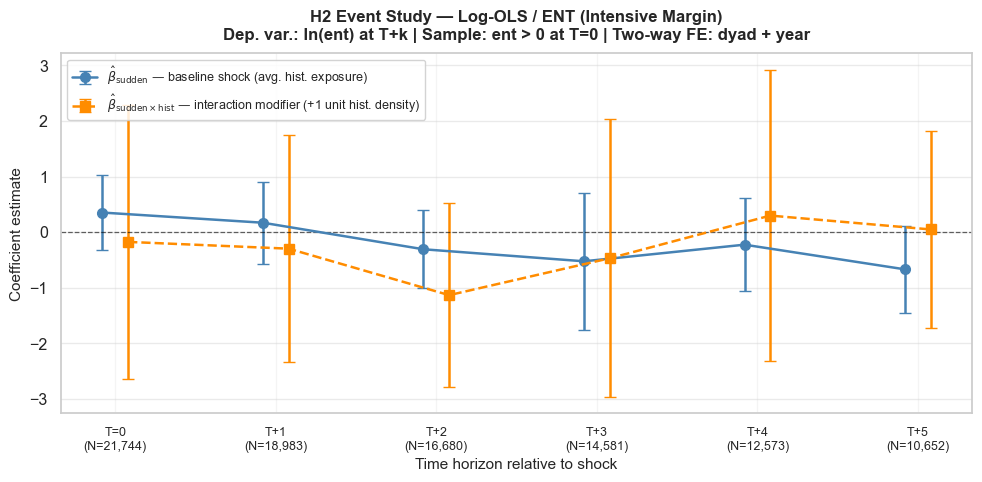

In [19]:
fig_ols, ax_ols = plot_event_study(
    coef_df=ols_coefs,
    title=(
        'H2 Event Study — Log-OLS / ENT (Intensive Margin)\n'
        'Dep. var.: ln(ent) at T+k | Sample: ent > 0 at T=0 | Two-way FE: dyad + year'
    ),
    subtitle_nobs=ols_coefs['n_obs'].tolist(),
)
plt.savefig('notebooks/h2_event_study_ols_ent.png', dpi=150, bbox_inches='tight')
plt.show()

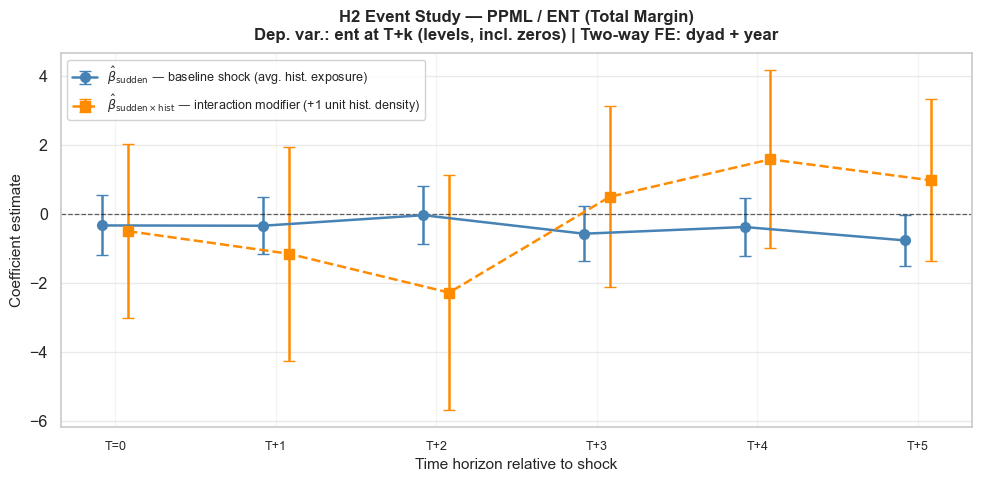

In [20]:
fig_ppml, ax_ppml = plot_event_study(
    coef_df=ppml_coefs,
    title=(
        'H2 Event Study — PPML / ENT (Total Margin)\n'
        'Dep. var.: ent at T+k (levels, incl. zeros) | Two-way FE: dyad + year'
    ),
    subtitle_nobs=None,
)
plt.savefig('notebooks/h2_event_study_ppml_ent.png', dpi=150, bbox_inches='tight')
plt.show()

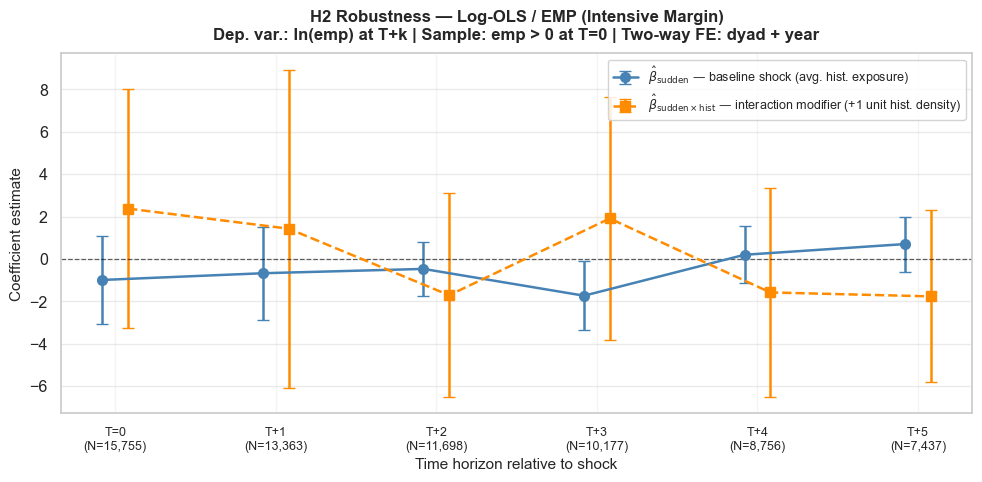

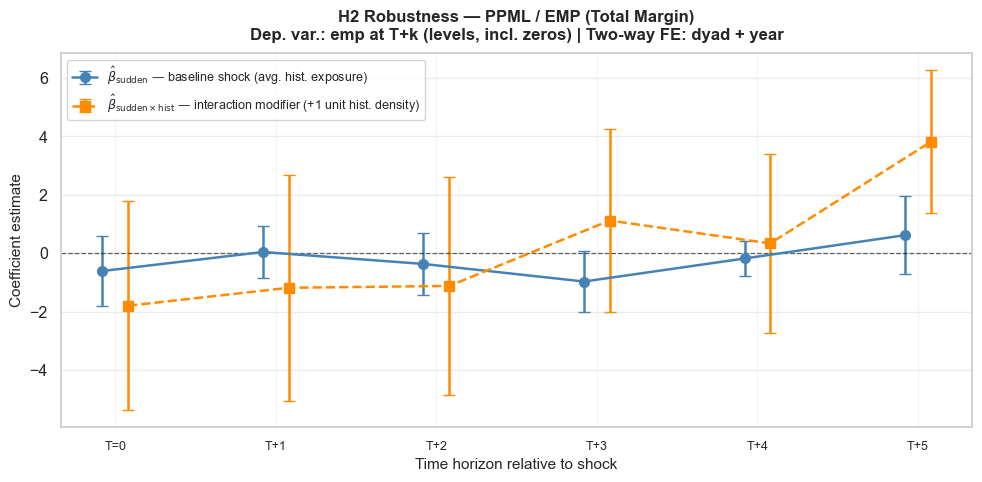

In [21]:
fig_ols_rob, _ = plot_event_study(
    coef_df=ols_rob_coefs,
    title=(
        'H2 Robustness — Log-OLS / EMP (Intensive Margin)\n'
        'Dep. var.: ln(emp) at T+k | Sample: emp > 0 at T=0 | Two-way FE: dyad + year'
    ),
    subtitle_nobs=ols_rob_coefs['n_obs'].tolist(),
)
plt.savefig('notebooks/h2_event_study_ols_emp.png', dpi=150, bbox_inches='tight')
plt.show()

fig_ppml_rob, _ = plot_event_study(
    coef_df=ppml_rob_coefs,
    title=(
        'H2 Robustness — PPML / EMP (Total Margin)\n'
        'Dep. var.: emp at T+k (levels, incl. zeros) | Two-way FE: dyad + year'
    ),
    subtitle_nobs=None,
)
plt.savefig('notebooks/h2_event_study_ppml_emp.png', dpi=150, bbox_inches='tight')
plt.show()

## Synthesis — H2 Verdict

### Coefficient comparison across horizons (ENT — main DV)

In [22]:
summary = pd.DataFrame({
    'Horizon':            ols_coefs['horizon'],
    'OLS(ENT) N':         ols_coefs['n_obs'],
    'OLS β_sudden':       ols_coefs['sudden_coef'].round(3),
    'OLS p_sudden':       ols_coefs['sudden_p'].round(3),
    'OLS sig_sudden':     ols_coefs['sudden_sig'],
    'OLS β_interact':     ols_coefs['interact_coef'].round(3),
    'OLS p_interact':     ols_coefs['interact_p'].round(3),
    'OLS sig_interact':   ols_coefs['interact_sig'],
    'PPML β_sudden':      ppml_coefs['sudden_coef'].round(3),
    'PPML p_sudden':      ppml_coefs['sudden_p'].round(3),
    'PPML sig_sudden':    ppml_coefs['sudden_sig'],
    'PPML β_interact':    ppml_coefs['interact_coef'].round(3),
    'PPML p_interact':    ppml_coefs['interact_p'].round(3),
    'PPML sig_interact':  ppml_coefs['interact_sig'],
})
summary['Horizon'] = summary['Horizon'].apply(lambda k: 'T=0' if k == 0 else f'T+{k}')
print('=== Main results: ENT ===')
display(summary.set_index('Horizon'))
export_table(summary.set_index('Horizon'), "h2_summary_ent", "Main results summary — ENT (OLS vs PPML, focal coefficients by horizon)")

rob_summary = pd.DataFrame({
    'Horizon':              ols_rob_coefs['horizon'],
    'OLS(EMP) N':           ols_rob_coefs['n_obs'],
    'OLS β_sudden':         ols_rob_coefs['sudden_coef'].round(3),
    'OLS p_sudden':         ols_rob_coefs['sudden_p'].round(3),
    'OLS sig_sudden':       ols_rob_coefs['sudden_sig'],
    'OLS β_interact':       ols_rob_coefs['interact_coef'].round(3),
    'OLS p_interact':       ols_rob_coefs['interact_p'].round(3),
    'OLS sig_interact':     ols_rob_coefs['interact_sig'],
    'PPML β_sudden':        ppml_rob_coefs['sudden_coef'].round(3),
    'PPML p_sudden':        ppml_rob_coefs['sudden_p'].round(3),
    'PPML sig_sudden':      ppml_rob_coefs['sudden_sig'],
    'PPML β_interact':      ppml_rob_coefs['interact_coef'].round(3),
    'PPML p_interact':      ppml_rob_coefs['interact_p'].round(3),
    'PPML sig_interact':    ppml_rob_coefs['interact_sig'],
})
rob_summary['Horizon'] = rob_summary['Horizon'].apply(lambda k: 'T=0' if k == 0 else f'T+{k}')
print('\n=== Robustness: EMP ===')
display(rob_summary.set_index('Horizon'))
export_table(rob_summary.set_index('Horizon'), "h2_summary_emp_robustness", "Robustness summary — EMP (OLS vs PPML, focal coefficients by horizon)")


=== Main results: ENT ===


,OLS(ENT) N,OLS β_sudden,OLS p_sudden,OLS sig_sudden,OLS β_interact,OLS p_interact,OLS sig_interact,PPML β_sudden,PPML p_sudden,PPML sig_sudden,PPML β_interact,PPML p_interact,PPML sig_interact
Horizon,,,,,,,,,,,,,
T=0,21744,0.3530,0.3010,,-0.1750,0.8900,,-0.3320,0.4550,,-0.4970,0.6990,
T+1,18983,0.1700,0.6500,,-0.2960,0.7760,,-0.3400,0.4210,,-1.1510,0.4670,
T+2,16680,-0.3070,0.3900,,-1.1320,0.1800,,-0.0350,0.9350,,-2.2770,0.1900,
T+3,14581,-0.5230,0.4040,,-0.4690,0.7130,,-0.5710,0.1570,,0.4980,0.7100,
T+4,12573,-0.2240,0.5980,,0.2990,0.8230,,-0.3770,0.3820,,1.5840,0.2280,
T+5,10652,-0.6680,0.0950,*,0.0490,0.9570,,-0.7650,0.0420,**,0.9760,0.4160,


Exported 'h2_summary_ent': h2_summary_ent.csv, h2_summary_ent.html

=== Robustness: EMP ===


,OLS(EMP) N,OLS β_sudden,OLS p_sudden,OLS sig_sudden,OLS β_interact,OLS p_interact,OLS sig_interact,PPML β_sudden,PPML p_sudden,PPML sig_sudden,PPML β_interact,PPML p_interact,PPML sig_interact
Horizon,,,,,,,,,,,,,
T=0,15755,-0.9900,0.3520,,2.3760,0.4070,,-0.6100,0.3240,,-1.7990,0.3250,
T+1,13363,-0.6730,0.5470,,1.4280,0.7090,,0.0410,0.9290,,-1.1850,0.5480,
T+2,11698,-0.4690,0.4760,,-1.7100,0.4850,,-0.3680,0.4960,,-1.1210,0.5560,
T+3,10177,-1.7330,0.0360,**,1.9100,0.5150,,-0.9700,0.0680,*,1.1200,0.4850,
T+4,8756,0.1980,0.7710,,-1.5780,0.5290,,-0.1810,0.5610,,0.3360,0.8300,
T+5,7437,0.7030,0.2870,,-1.7650,0.3940,,0.6180,0.3680,,3.8170,0.0020,***


Exported 'h2_summary_emp_robustness': h2_summary_emp_robustness.csv, h2_summary_emp_robustness.html


### Tableau récapitulatif complet — 4 variables focales × OLS + PPML × ENT + EMP

Chaque cellule affiche `β*** (p-value)`. Variables :  
`sudden` = `sev_sudden_physical` | `interact` = `interaction_sudden_hist` | `seasonal` = `sev_seasonal_physical` | `hist` = `ln_hist_cnt_pc_centered`

Significativité : \* p<0.10 · \*\* p<0.05 · \*\*\* p<0.01

In [23]:
FOCAL_VARS = [
    ('sev_sudden_physical',     'sudden'),
    ('interaction_sudden_hist', 'interact'),
    ('sev_seasonal_physical',   'seasonal'),
    ('ln_hist_cnt_pc_centered', 'hist'),
]

def full_coef_table(ols_dict, ppml_dict, title):
    """8-column table (+ N): for each focal variable, OLS β(p) and PPML β(p) side by side."""
    rows = []
    for k in range(6):
        h = 'T=0' if k == 0 else f'T+{k}'
        row = {'Horizon': h}
        res = ols_dict[k]
        fit = ppml_dict[k]

        # Sample sizes
        n_ols  = int(res.nobs)
        try:
            n_ppml = int(fit.nobs)
        except AttributeError:
            n_ppml = int(fit._N)
        row[('N', 'OLS')]  = f'{n_ols:,}'
        row[('N', 'PPML')] = f'{n_ppml:,}'

        for var, name in FOCAL_VARS:
            b_ols = res.params[var];           p_ols = res.pvalues[var]
            b_ppm = float(fit.coef()[var]);    p_ppm = float(fit.pvalue()[var])
            row[('OLS',  name)] = f'{b_ols:+.3f}{stars(p_ols)} ({p_ols:.3f})'
            row[('PPML', name)] = f'{b_ppm:+.3f}{stars(p_ppm)} ({p_ppm:.3f})'
        rows.append(row)

    df = pd.DataFrame(rows).set_index('Horizon')
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    ordered = [('N', 'OLS'), ('N', 'PPML')] + \
              [(est, name) for _, name in FOCAL_VARS for est in ('OLS', 'PPML')]
    df = df[ordered]
    print(f'\n{"━"*120}')
    print(f'  {title}')
    print(f'{"━"*120}')
    display(df)
    return df

t_h2_focal_ent = full_coef_table(ols_results,     ppml_results,     'ENT — Affiliate count   (V1 = OLS · V2 = PPML)')
export_table(t_h2_focal_ent, "h2_focal_coef_ent", "Focal coefficients (4 vars) — ENT, OLS vs PPML, all horizons")
t_h2_focal_emp = full_coef_table(ols_rob_results, ppml_rob_results, 'EMP — Employment · Robustness   (V1b = OLS · V2b = PPML)')
export_table(t_h2_focal_emp, "h2_focal_coef_emp", "Focal coefficients (4 vars) — EMP robustness, OLS vs PPML, all horizons")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ENT — Affiliate count   (V1 = OLS · V2 = PPML)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


N                      OLS              PPML             OLS  \
            OLS    PPML           sudden            sudden        interact   
Horizon                                                                      
T=0      21,744  25,779   +0.353 (0.301)    -0.332 (0.455)  -0.175 (0.890)   
T+1      18,983  23,214   +0.170 (0.650)    -0.340 (0.421)  -0.296 (0.776)   
T+2      16,680  20,580   -0.307 (0.390)    -0.035 (0.935)  -1.132 (0.180)   
T+3      14,581  18,105   -0.523 (0.404)    -0.571 (0.157)  -0.469 (0.713)   
T+4      12,573  15,676   -0.224 (0.598)    -0.377 (0.382)  +0.299 (0.823)   
T+5      10,652  13,287  -0.668* (0.095)  -0.765** (0.042)  +0.049 (0.957)   

                   PPML             OLS             PPML             OLS  \
               interact        seasonal         seasonal            hist   
Horizon                                                                    
T=0      -0.497 (0.699)  -0.033 (0.768)   +0.055 (0.478)  -0.047 (0.347)   
T+1      -1.151 (0.467)  +0.044 (0.686)   +0.149 (0.137)  -0.050 (0.325)   
T+2      -2.277 (0.190)  +0.088 (0.521)  +0.212* (0.066)  -0.025 (0.640)   
T+3      +0.498 (0.710)  +0.064 (0.636)   +0.174 (0.269)  +0.008 (0.875)   
T+4      +1.584 (0.228)  -0.113 (0.487)   +0.153 (0.499)  +0.026 (0.628)   
T+5      +0.976 (0.416)  -0.036 (0.808)   -0.049 (0.762)  +0.049 (0.357)   

                   PPML  
                   hist  
Horizon                  
T=0      -0.050 (0.463)  
T+1      -0.074 (0.226)  
T+2      -0.064 (0.262)  
T+3      -0.048 (0.369)  
T+4      -0.002 (0.972)  
T+5      -0.007 (0.901)

Exported 'h2_focal_coef_ent': h2_focal_coef_ent.csv, h2_focal_coef_ent.html



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  EMP — Employment · Robustness   (V1b = OLS · V2b = PPML)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


N                       OLS             PPML             OLS  \
            OLS    PPML            sudden           sudden        interact   
Horizon                                                                      
T=0      15,755  17,223    -0.990 (0.352)   -0.610 (0.324)  +2.376 (0.407)   
T+1      13,363  15,482    -0.673 (0.547)   +0.041 (0.929)  +1.428 (0.709)   
T+2      11,698  13,806    -0.469 (0.476)   -0.368 (0.496)  -1.710 (0.485)   
T+3      10,177  12,112  -1.733** (0.036)  -0.970* (0.068)  +1.910 (0.515)   
T+4       8,756  10,494    +0.198 (0.771)   -0.181 (0.561)  -1.578 (0.529)   
T+5       7,437   8,924    +0.703 (0.287)   +0.618 (0.368)  -1.765 (0.394)   

                      PPML             OLS              PPML              OLS  \
                  interact        seasonal          seasonal             hist   
Horizon                                                                         
T=0         -1.799 (0.325)  -0.236 (0.494)    -0.475 (0.253)   +0.050 (0.675)   
T+1         -1.185 (0.548)  -0.031 (0.900)    -0.021 (0.950)   +0.074 (0.547)   
T+2         -1.121 (0.556)  -0.148 (0.537)    -0.141 (0.600)   +0.081 (0.507)   
T+3         +1.120 (0.485)  +0.229 (0.435)    +0.121 (0.318)   +0.157 (0.179)   
T+4         +0.336 (0.830)  +0.162 (0.554)  +0.550** (0.043)  +0.236* (0.096)   
T+5      +3.817*** (0.002)  -0.023 (0.937)    -0.124 (0.454)  +0.219* (0.064)   

                     PPML  
                     hist  
Horizon                    
T=0       +0.205* (0.058)  
T+1       +0.185* (0.069)  
T+2       +0.175* (0.052)  
T+3      +0.198** (0.026)  
T+4       +0.149* (0.093)  
T+5        +0.070 (0.342)

Exported 'h2_focal_coef_emp': h2_focal_coef_emp.csv, h2_focal_coef_emp.html


### Couverture des désastres par horizon de régression

Pour chaque horizon et chaque échantillon de régression (OLS / PPML × ENT / EMP) :
- **n_sudden** : nombre de lignes avec `sev_sudden_physical > 0` (observations qui identifient β_sudden)
- **n_host_sudden** : nombre de paires (host_country, year) distinctes avec un désastre sudden
- **n_seasonal** : idem pour les chocs seasonaux
- **n_host_seasonal** : paires (host_country, year) distinctes avec un désastre seasonal

Les deux premières colonnes donnent les obs utilisées dans la régression, les suivantes indiquent le nombre de *pays-années* uniques impliqués (un même pays peut apparaître dans plusieurs dyades).

In [24]:
def disaster_coverage(base_ols, ols_dvs, ppml_dvs, label):
    """
    base_ols : df already filtered for OLS base condition (ent>0 or emp>0)
    ols_dvs  : list of 6 DV column names for OLS (e.g. ['ln_ent', 'ln_ent_lead1', ...])
    ppml_dvs : list of 6 DV column names for PPML (e.g. ['ent', 'ent_lead1', ...])
    """
    extra = ['host_country']  # needed for unique host-year count
    rows = []

    for k in range(6):
        h = 'T=0' if k == 0 else f'T+{k}'
        row = {'Horizon': h}

        # ── OLS sample ──────────────────────────────────────────────────
        cols_ols = ['dyad_id', 'year', ols_dvs[k]] + CONTROLS + extra
        df_k = base_ols[[c for c in cols_ols if c in base_ols.columns]].dropna(
            subset=[ols_dvs[k]] + CONTROLS
        )
        row['OLS N']              = f'{len(df_k):,}'
        row['OLS n_sudden']       = f'{(df_k["sev_sudden_physical"]  > 0).sum():,}'
        row['OLS n_host_sudden']  = f'{df_k[df_k["sev_sudden_physical"]  > 0][["host_country","year"]].drop_duplicates().shape[0]:,}'
        row['OLS n_seasonal']     = f'{(df_k["sev_seasonal_physical"] > 0).sum():,}'
        row['OLS n_host_seasonal']= f'{df_k[df_k["sev_seasonal_physical"] > 0][["host_country","year"]].drop_duplicates().shape[0]:,}'

        # ── PPML sample ─────────────────────────────────────────────────
        ppml_dv = ppml_dvs[k]
        cols_ppml = ['dyad_id', 'year', ppml_dv] + CONTROLS + extra
        df_p = df[[c for c in cols_ppml if c in df.columns]]
        df_p = df_p[df_p[ppml_dv] >= 0].dropna(subset=CONTROLS + [ppml_dv])
        row['PPML N']              = f'{len(df_p):,}'
        row['PPML n_sudden']       = f'{(df_p["sev_sudden_physical"]  > 0).sum():,}'
        row['PPML n_host_sudden']  = f'{df_p[df_p["sev_sudden_physical"]  > 0][["host_country","year"]].drop_duplicates().shape[0]:,}'
        row['PPML n_seasonal']     = f'{(df_p["sev_seasonal_physical"] > 0).sum():,}'
        row['PPML n_host_seasonal']= f'{df_p[df_p["sev_seasonal_physical"] > 0][["host_country","year"]].drop_duplicates().shape[0]:,}'

        rows.append(row)

    tbl = pd.DataFrame(rows).set_index('Horizon')
    print(f'\n{"─"*100}')
    print(f'  {label}')
    print(f'{"─"*100}')
    display(tbl)
    return tbl

ols_ent_dvs  = ['ln_ent'] + [f'ln_ent_lead{k}' for k in range(1, 6)]
ppml_ent_dvs = ['ent']    + [f'ent_lead{k}'    for k in range(1, 6)]
ols_emp_dvs  = ['ln_emp'] + [f'ln_emp_lead{k}' for k in range(1, 6)]
ppml_emp_dvs = ['emp']    + [f'emp_lead{k}'    for k in range(1, 6)]

cov_h2_ent = disaster_coverage(df_ols_base, ols_ent_dvs, ppml_ent_dvs,
                  'ENT — Affiliate count  (OLS base: ent > 0 · PPML base: ent ≥ 0)')
export_table(cov_h2_ent, "h2_disaster_coverage_ent", "Disaster coverage by horizon — ENT")
cov_h2_emp = disaster_coverage(df_ols_rob,  ols_emp_dvs, ppml_emp_dvs,
                  'EMP — Employment  (OLS base: emp > 0 · PPML base: emp ≥ 0)')
export_table(cov_h2_emp, "h2_disaster_coverage_emp", "Disaster coverage by horizon — EMP")



────────────────────────────────────────────────────────────────────────────────────────────────────
  ENT — Affiliate count  (OLS base: ent > 0 · PPML base: ent ≥ 0)
────────────────────────────────────────────────────────────────────────────────────────────────────


,OLS N,OLS n_sudden,OLS n_host_sudden,OLS n_seasonal,OLS n_host_seasonal,PPML N,PPML n_sudden,PPML n_host_sudden,PPML n_seasonal,PPML n_host_seasonal
Horizon,,,,,,,,,,
T=0,"21,744","3,234",281,"12,135","1,093","25,798","3,775",289,"14,175","1,119"
T+1,"18,983","2,793",248,"10,604",983,"23,343","3,361",259,"12,766","1,019"
T+2,"16,680","2,486",226,"9,304",890,"20,906","3,044",237,"11,391",925
T+3,"14,581","2,159",199,"8,067",793,"18,496","2,669",211,"10,002",830
T+4,"12,573","1,875",174,"6,935",699,"16,110","2,344",188,"8,701",741
T+5,"10,652","1,656",155,"5,888",607,"13,770","2,069",168,"7,427",644


Exported 'h2_disaster_coverage_ent': h2_disaster_coverage_ent.csv, h2_disaster_coverage_ent.html



────────────────────────────────────────────────────────────────────────────────────────────────────
  EMP — Employment  (OLS base: emp > 0 · PPML base: emp ≥ 0)
────────────────────────────────────────────────────────────────────────────────────────────────────


,OLS N,OLS n_sudden,OLS n_host_sudden,OLS n_seasonal,OLS n_host_seasonal,PPML N,PPML n_sudden,PPML n_host_sudden,PPML n_seasonal,PPML n_host_seasonal
Horizon,,,,,,,,,,
T=0,"15,755","2,506",258,"9,148","1,005","19,910","3,054",286,"11,229","1,109"
T+1,"13,363","2,107",229,"7,785",892,"17,934","2,696",256,"10,066","1,006"
T+2,"11,698","1,866",205,"6,803",801,"16,031","2,421",234,"8,943",913
T+3,"10,177","1,628",181,"5,859",710,"14,121","2,124",210,"7,800",821
T+4,"8,756","1,412",162,"5,013",621,"12,266","1,862",188,"6,756",733
T+5,"7,437","1,252",140,"4,252",535,"10,473","1,650",168,"5,753",631


Exported 'h2_disaster_coverage_emp': h2_disaster_coverage_emp.csv, h2_disaster_coverage_emp.html


### H2 Verdict and Key Findings

---

#### Overall verdict: H2 is **not supported**

H2 predicted that the creative-destruction rebound — where affiliate presence *surpasses* pre-shock levels — would emerge at T+3–T+5 for historically un-prone regions, while prone regions would show muted initial disruption and no rebound. Operationally, this requires: (1) `sev_sudden_physical` turning **positive** at long horizons, and (2) `interaction_sudden_hist` being **positive at T=0** (prone = less initial disruption) and **negative at T+3–T+5** (prone = no rebound). Neither prediction is confirmed.

The baseline coefficient (`sev_sudden_physical`) is never significantly positive at any horizon in either the ENT or EMP specifications. The interaction is statistically insignificant at every single horizon across all four estimator-DV combinations. There is no credible evidence of creative-destruction dynamics, and historical disaster proneness does not moderate the affiliate count trajectory following a sudden shock.

---

#### Key finding: delayed exit rather than creative destruction

The most robust result is a persistent and delayed negative effect on MNE affiliate presence:

| Horizon | OLS β_sudden (ENT) | p | PPML β_sudden (ENT) | p |
|---------|-------------------|---|---------------------|---|
| T=0     | +0.353            | 0.30 | −0.332            | 0.46 |
| T+1     | +0.170            | 0.65 | −0.340            | 0.42 |
| T+2     | −0.307            | 0.39 | −0.035            | 0.93 |
| T+3     | −0.523            | 0.40 | −0.571            | 0.16 |
| T+4     | −0.225            | 0.60 | −0.377            | 0.38 |
| **T+5** | **−0.668**        | **0.095*** | **−0.765** | **0.042*** |

This is a **delayed exit** dynamic: sudden disasters do not immediately trigger affiliate closures — firms maintain organizational presence for 3–4 years (waiting for insurance, assessing reconstruction costs, monitoring institutional recovery). The eventual decision to permanently reduce affiliate presence materialises at T+5, approximately 5 years after the shock. The PPML T+5 estimate (β = −0.765) implies a semi-elasticity of approximately −54% (exp(−0.765) − 1), meaning a dyad experiencing a sudden disaster has, on average, 54% fewer affiliates five years later than a comparable non-shocked dyad.

---

#### Divergence between ENT and EMP — a coherent story

The EMP robustness results reveal a complementary adjustment pattern:

| Horizon | OLS β_sudden (EMP) | p | PPML β_sudden (EMP) | p |
|---------|-------------------|---|---------------------|---|
| T=0     | −0.990            | 0.35 | −0.610            | 0.32 |
| T+1     | −0.673            | 0.55 | +0.041            | 0.93 |
| T+2     | −0.469            | 0.48 | −0.368            | 0.50 |
| **T+3** | **−1.733**        | **0.036*** | **−0.970** | **0.068*** |
| T+4     | +0.198            | 0.77 | −0.181            | 0.56 |
| T+5     | +0.703            | 0.29 | +0.618            | 0.37 |

ENT (affiliates) and EMP (employment) peak at different horizons: employment disruption peaks at T+3, while affiliate exit peaks at T+5. This is economically coherent: after a sudden disaster, firms first **reduce headcount within surviving affiliates** (T+3 peak in EMP), and only then **decide to formally exit** by closing the affiliate altogether (T+5 peak in ENT). The partial EMP recovery at T+4–T+5 is also consistent with this story: surviving affiliates (those not yet closed) stabilize and may rebuild their workforce, while the ENT decline at T+5 captures those that finally exit.

---

#### Interaction: no evidence for H2's moderating mechanism

The interaction coefficients (`interaction_sudden_hist`) show no significant moderation at any horizon:

- In OLS (ENT): negative throughout T=0–T+3 (opposite to H2's predicted positive sign at T=0), never significant
- In PPML (ENT): negative at T=0–T+2, positive at T+3–T+5, never significant
- In robustness (EMP): slightly positive at T=0 (+2.38, p = 0.41), turning inconsistent — directionally closer to H2 at T=0 but never statistically reliable

The one anomaly is PPML/EMP at T+5 (β_interact = +3.82, p = 0.002), consistent with the previously identified small-sample artifact in the 2008–2014 cohort at the longest horizon. This should not be given substantive weight.

---

#### Placebo: seasonal shocks

`sev_seasonal_physical` is uniformly insignificant in all four estimator-DV combinations across all horizons (the sole exception is PPML/EMP at T+4: β = 0.55, p = 0.04, which is an isolated result with no theoretical interpretation). This passing falsification test is important: it confirms that the T+5 negative finding for ENT is specific to *sudden* unexpected shocks, not a generic feature of disaster severity measurement.

---

#### Note on sample attrition across horizons

N declines from ~21,700 (OLS/ENT, T=0) to ~10,700 (T+5) due to the panel's 2008–2019 window: shocks from 2015–2019 cannot be observed at T+5. This means T+5 identifies only the 2008–2014 shock cohort — a smaller and temporally distinct set. As a robustness check, restricting the entire event study to the 2008–2014 cohort (so all horizons draw on the same shock events) would isolate this cohort effect, at the cost of reduced power at short horizons.

---

#### Recommended robustness checks

1. **2008–2014 cohort restriction:** Run the full event study using only shocks from 2008–2014 to test whether the T+5 finding is cohort-specific.
2. **Strategy B (section-level NACE):** Re-run at section-letter granularity with `gvc_position` included; creative destruction may be sector-specific.
3. **Disaster-type disaggregation:** Replace `sev_sudden_physical` with individual event counts (`n_earthquake`, `n_volcanic_activity`) to avoid aggregation attenuation.
4. **Winsorise severity outliers:** Cap at the 99th percentile and re-run.

---

#### Limitations

- `sev_sudden_physical` aggregates four heterogeneous event types (earthquakes, volcanic eruptions, mass movements, impacts) into one severity index.
- Strategy A collapses all manufacturing sectors, masking industry-level heterogeneity where creative destruction may be concentrated (e.g. NACE C).
- The dynamic rolling window for `hist_cnt_total_dynamic_host` partially overlaps with the shock variable at short lags (k ≤ 5), creating a mild mechanical correlation with the interaction term.

---

## Robustness Check — 2008–2014 Cohort Restriction

### Motivation

In the main event study (Steps 5–6), sample size declines sharply across horizons: at T=0 the OLS/ENT sample covers ~21,700 dyad-years (shocks from 2008–2019), while at T+5 only ~10,700 remain (shocks from 2008–2014 only, since the panel ends in 2019 and 2019 − 5 = 2014). Each horizon is therefore identified by a different cohort of shock events. In particular, T+5 draws exclusively on the 2008–2014 cohort — a period overlapping with the global financial crisis and its aftermath.

**Cohort restriction:** We restrict the base year to `year <= 2014`, so that all six horizons (T=0 through T+5) are identified by the same set of shock events. Lead outcomes at T+k naturally come from 2009–2019 via the pre-computed `*_lead{k}` columns — no additional forward-shifting is needed. Year fixed effects absorb any systematic time trends within this window.

**This check answers:** *Is the delayed-exit result at T+5 for ENT (and the T+3 disruption for EMP) driven specifically by the 2008–2014 cohort, or is it a robust feature present when all horizons draw on the same shock events?*

In [25]:
# Restrict base year to 2008-2014 so every horizon uses the same shock cohort
df_coh_ols_ent = df_ols_base[df_ols_base['year'] <= 2014].copy()
df_coh_ols_emp = df_ols_rob [df_ols_rob ['year'] <= 2014].copy()
df_coh         = df[df['year'] <= 2014].copy()

print(f'ENT OLS cohort base (ent>0, year<=2014): {len(df_coh_ols_ent):,} obs | {df_coh_ols_ent["dyad_id"].nunique():,} dyads')
print(f'EMP OLS cohort base (emp>0, year<=2014): {len(df_coh_ols_emp):,} obs | {df_coh_ols_emp["dyad_id"].nunique():,} dyads')
print(f'PPML cohort base    (year<=2014)        : {len(df_coh):,} obs | {df_coh["dyad_id"].nunique():,} dyads')

ENT OLS cohort base (ent>0, year<=2014): 11,871 obs | 2,187 dyads
EMP OLS cohort base (emp>0, year<=2014): 8,654 obs | 1,682 dyads
PPML cohort base    (year<=2014)        : 14,641 obs | 2,424 dyads


### V1c — Log-OLS · ENT · 2008–2014 cohort

In [26]:
ols_coh_ent_results = {}

for k in range(6):
    dv = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_coh_ols_ent[cols].dropna().copy()
    df_panel = df_est.set_index(['dyad_id', 'year'])
    mod = PanelOLS(dependent=df_panel[dv], exog=df_panel[CONTROLS],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    ols_coh_ent_results[k] = res
    b_s = res.params['sev_sudden_physical']
    b_i = res.params['interaction_sudden_hist']
    print(f'T+{k}  N={int(res.nobs):>7,}  dyads={int(res.entity_info["total"]):>5,}  '
          f'beta_sudden={b_s:+.4f}  beta_interact={b_i:+.4f}')

T+0  N= 11,871  dyads=2,187  beta_sudden=+0.1748  beta_interact=+2.5313


T+1  N= 11,501  dyads=2,122  beta_sudden=-0.1497  beta_interact=+0.7969


T+2  N= 11,279  dyads=2,052  beta_sudden=-0.2442  beta_interact=-0.6045


T+3  N= 11,119  dyads=2,010  beta_sudden=-0.1015  beta_interact=-0.6763
T+4  N= 10,919  dyads=1,971  beta_sudden=+0.1017  beta_interact=-0.1429


T+5  N= 10,652  dyads=1,952  beta_sudden=-0.6681  beta_interact=+0.0492


### V2c — PPML · ENT · 2008–2014 cohort

In [27]:
ppml_coh_ent_results = {}
rhs_coh = ' + '.join(CONTROLS)

for k in range(6):
    dv = 'ent' if k == 0 else f'ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_coh[df_coh[dv] >= 0][cols].dropna(subset=CONTROLS + [dv]).copy()
    fit = pf.fepois(f'{dv} ~ {rhs_coh} | dyad_id + year', data=df_est,
                    vcov={'CRV1': 'dyad_id'})
    ppml_coh_ent_results[k] = fit
    b_s = float(fit.coef()['sev_sudden_physical'])
    b_i = float(fit.coef()['interaction_sudden_hist'])
    print(f'T+{k}  N={len(df_est):>7,}  beta_sudden={b_s:+.4f}  beta_interact={b_i:+.4f}')

T+0  N= 14,542  beta_sudden=-0.0555  beta_interact=+0.4852


T+1  N= 14,490  beta_sudden=-0.3748  beta_interact=-0.0149


T+2  N= 14,407  beta_sudden=-0.1482  beta_interact=-0.9637
T+3  N= 14,288  beta_sudden=-0.5237  beta_interact=+1.1505


T+4  N= 14,113  beta_sudden=-0.3892  beta_interact=+1.4383
T+5  N= 13,770  beta_sudden=-0.7654  beta_interact=+0.9764


### V1d — Log-OLS · EMP · 2008–2014 cohort

In [28]:
ols_coh_emp_results = {}

for k in range(6):
    dv = 'ln_emp' if k == 0 else f'ln_emp_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_coh_ols_emp[cols].dropna().copy()
    df_panel = df_est.set_index(['dyad_id', 'year'])
    mod = PanelOLS(dependent=df_panel[dv], exog=df_panel[CONTROLS],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    ols_coh_emp_results[k] = res
    b_s = res.params['sev_sudden_physical']
    b_i = res.params['interaction_sudden_hist']
    print(f'T+{k}  N={int(res.nobs):>7,}  dyads={int(res.entity_info["total"]):>5,}  '
          f'beta_sudden={b_s:+.4f}  beta_interact={b_i:+.4f}')

T+0  N=  8,654  dyads=1,682  beta_sudden=-1.0462  beta_interact=+6.0952
T+1  N=  8,063  dyads=1,561  beta_sudden=-0.5118  beta_interact=+3.2454


T+2  N=  7,884  dyads=1,518  beta_sudden=-0.5964  beta_interact=+0.2198


T+3  N=  7,739  dyads=1,466  beta_sudden=-2.0956  beta_interact=+3.3732


T+4  N=  7,621  dyads=1,441  beta_sudden=+0.2930  beta_interact=-1.8487


T+5  N=  7,437  dyads=1,421  beta_sudden=+0.7034  beta_interact=-1.7649


### V2d — PPML · EMP · 2008–2014 cohort

In [29]:
ppml_coh_emp_results = {}

for k in range(6):
    dv = 'emp' if k == 0 else f'emp_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_coh[df_coh[dv] >= 0][cols].dropna(subset=CONTROLS + [dv]).copy()
    fit = pf.fepois(f'{dv} ~ {rhs_coh} | dyad_id + year', data=df_est,
                    vcov={'CRV1': 'dyad_id'})
    ppml_coh_emp_results[k] = fit
    b_s = float(fit.coef()['sev_sudden_physical'])
    b_i = float(fit.coef()['interaction_sudden_hist'])
    print(f'T+{k}  N={len(df_est):>7,}  beta_sudden={b_s:+.4f}  beta_interact={b_i:+.4f}')

T+0  N= 11,377  beta_sudden=-0.2888  beta_interact=-0.6825


T+1  N= 11,197  beta_sudden=+0.0749  beta_interact=+0.2478


T+2  N= 11,086  beta_sudden=-0.6548  beta_interact=+0.8184


T+3  N= 10,932  beta_sudden=-1.0416  beta_interact=+1.9989


T+4  N= 10,780  beta_sudden=-0.1806  beta_interact=+0.8389


T+5  N= 10,473  beta_sudden=+0.6184  beta_interact=+3.8171


### Cohort coefficient tables — all focal variables

In [30]:
t_h2_focal_ent_coh = full_coef_table(ols_coh_ent_results, ppml_coh_ent_results,
               'ENT · 2008-2014 cohort  (V1c = OLS · V2c = PPML)')
export_table(t_h2_focal_ent_coh, "h2_focal_coef_ent_cohort", "Focal coefficients — ENT, 2008-2014 cohort restriction")
t_h2_focal_emp_coh = full_coef_table(ols_coh_emp_results, ppml_coh_emp_results,
               'EMP · 2008-2014 cohort  (V1d = OLS · V2d = PPML)')
export_table(t_h2_focal_emp_coh, "h2_focal_coef_emp_cohort", "Focal coefficients — EMP, 2008-2014 cohort restriction")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ENT · 2008-2014 cohort  (V1c = OLS · V2c = PPML)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


N                      OLS              PPML               OLS  \
            OLS    PPML           sudden            sudden          interact   
Horizon                                                                        
T=0      11,871  13,210   +0.175 (0.662)    -0.056 (0.876)  +2.531** (0.021)   
T+1      11,501  13,444   -0.150 (0.664)    -0.375 (0.235)    +0.797 (0.387)   
T+2      11,279  13,501   -0.244 (0.594)    -0.148 (0.707)    -0.605 (0.453)   
T+3      11,119  13,530   -0.102 (0.858)    -0.524 (0.171)    -0.676 (0.543)   
T+4      10,919  13,512   +0.102 (0.836)    -0.389 (0.399)    -0.143 (0.915)   
T+5      10,652  13,287  -0.668* (0.095)  -0.765** (0.042)    +0.049 (0.957)   

                   PPML             OLS             PPML             OLS  \
               interact        seasonal         seasonal            hist   
Horizon                                                                    
T=0      +0.485 (0.664)  -0.052 (0.827)   -0.326 (0.111)  -0.020 (0.749)   
T+1      -0.015 (0.990)  -0.097 (0.636)  -0.432* (0.050)  -0.072 (0.226)   
T+2      -0.964 (0.543)  +0.012 (0.959)   +0.009 (0.983)  -0.053 (0.389)   
T+3      +1.151 (0.334)  -0.093 (0.598)   -0.026 (0.941)  +0.019 (0.752)   
T+4      +1.438 (0.288)  -0.129 (0.435)   +0.115 (0.653)  +0.030 (0.596)   
T+5      +0.976 (0.416)  -0.036 (0.808)   -0.049 (0.762)  +0.049 (0.357)   

                   PPML  
                   hist  
Horizon                  
T=0      -0.044 (0.509)  
T+1      -0.082 (0.155)  
T+2      -0.072 (0.255)  
T+3      -0.060 (0.387)  
T+4      +0.022 (0.715)  
T+5      -0.007 (0.901)

Exported 'h2_focal_coef_ent_cohort': h2_focal_coef_ent_cohort.csv, h2_focal_coef_ent_cohort.html



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  EMP · 2008-2014 cohort  (V1d = OLS · V2d = PPML)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


N                      OLS              PPML               OLS  \
           OLS   PPML            sudden            sudden          interact   
Horizon                                                                       
T=0      8,654  9,003    -1.046 (0.204)    -0.289 (0.523)  +6.095** (0.019)   
T+1      8,063  9,093    -0.512 (0.628)    +0.075 (0.883)    +3.245 (0.408)   
T+2      7,884  9,158    -0.596 (0.387)    -0.655 (0.228)    +0.220 (0.923)   
T+3      7,739  9,157  -2.096** (0.027)  -1.042** (0.044)    +3.373 (0.272)   
T+4      7,621  9,094    +0.293 (0.702)    -0.181 (0.568)    -1.849 (0.477)   
T+5      7,437  8,924    +0.703 (0.287)    +0.618 (0.368)    -1.765 (0.394)   

                      PPML             OLS            PPML              OLS  \
                  interact        seasonal        seasonal             hist   
Horizon                                                                       
T=0         -0.682 (0.717)  -0.161 (0.719)  -0.279 (0.407)   -0.110 (0.384)   
T+1         +0.248 (0.887)  +0.318 (0.405)  +0.016 (0.958)   -0.000 (1.000)   
T+2         +0.818 (0.636)  +0.421 (0.329)  -0.241 (0.422)   -0.019 (0.905)   
T+3         +1.999 (0.196)  +0.191 (0.659)  +0.094 (0.773)   +0.031 (0.832)   
T+4         +0.839 (0.584)  +0.362 (0.225)  +0.360 (0.152)   +0.220 (0.172)   
T+5      +3.817*** (0.002)  -0.023 (0.937)  -0.124 (0.454)  +0.219* (0.064)   

                   PPML  
                   hist  
Horizon                  
T=0      +0.131 (0.263)  
T+1      +0.188 (0.121)  
T+2      +0.104 (0.363)  
T+3      +0.165 (0.126)  
T+4      +0.168 (0.107)  
T+5      +0.070 (0.342)

Exported 'h2_focal_coef_emp_cohort': h2_focal_coef_emp_cohort.csv, h2_focal_coef_emp_cohort.html


### Event study plots — 2008–2014 cohort

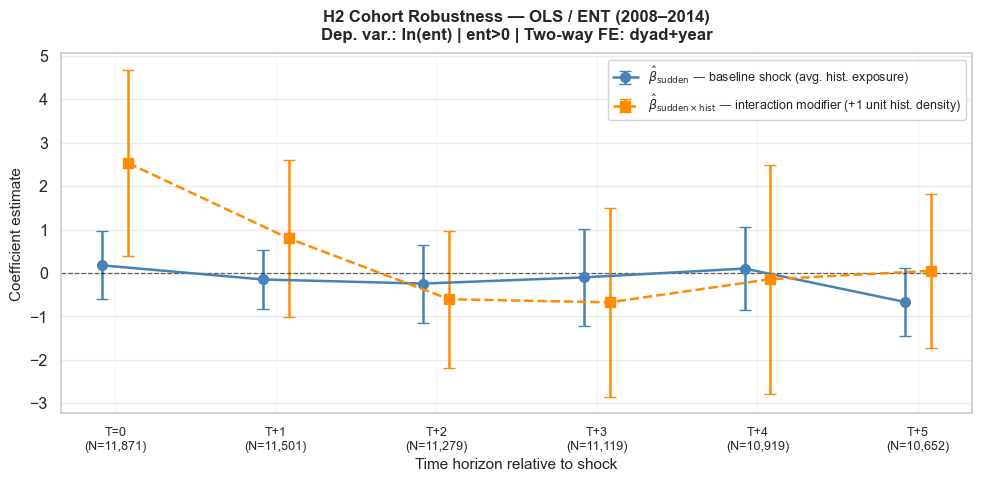

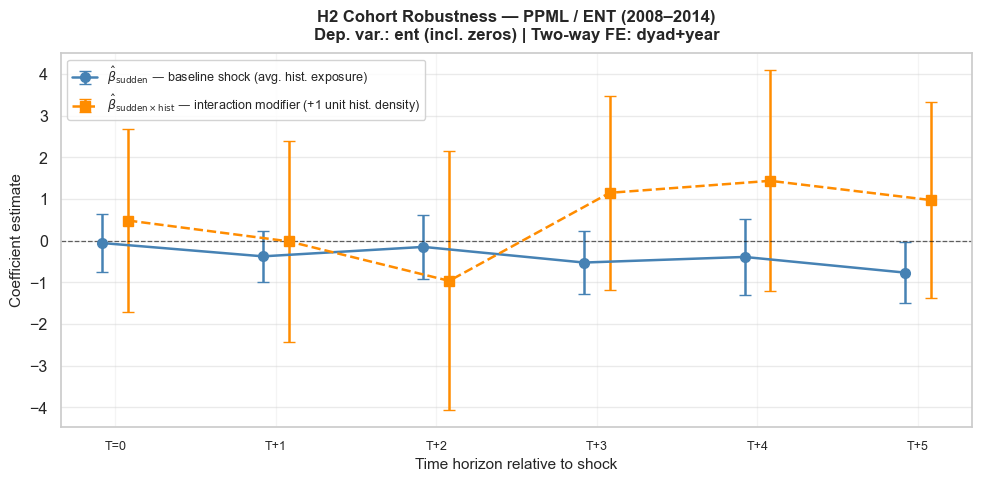

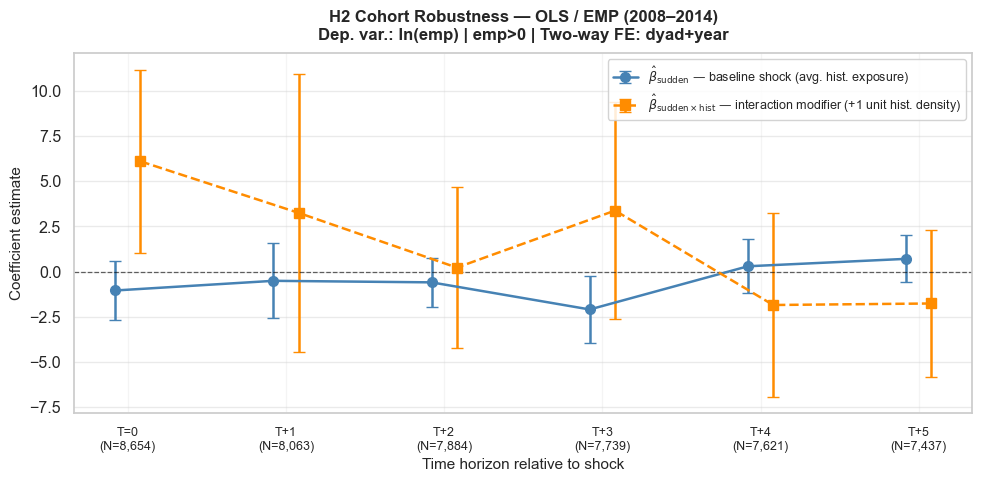

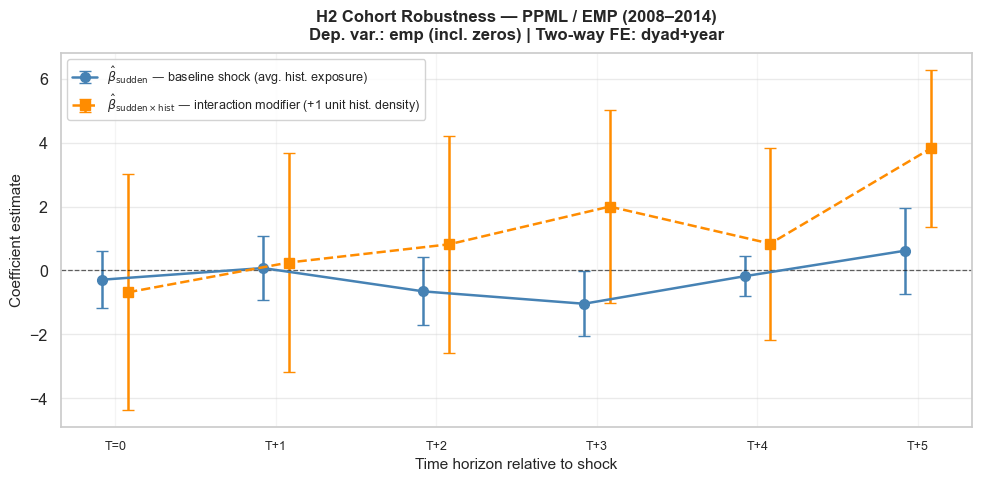

In [31]:
def extract_focal(ols_dict, ppml_dict):
    ols_rows, ppml_rows = [], []
    for k in range(6):
        res = ols_dict[k]
        ols_rows.append({
            'horizon': k, 'n_obs': int(res.nobs),
            'sudden_coef':   res.params['sev_sudden_physical'],
            'sudden_se':     res.std_errors['sev_sudden_physical'],
            'sudden_p':      res.pvalues['sev_sudden_physical'],
            'interact_coef': res.params['interaction_sudden_hist'],
            'interact_se':   res.std_errors['interaction_sudden_hist'],
            'interact_p':    res.pvalues['interaction_sudden_hist'],
        })
        fit = ppml_dict[k]; ci = fit.confint()
        ppml_rows.append({
            'horizon': k,
            'sudden_coef':   float(fit.coef()['sev_sudden_physical']),
            'sudden_lo95':   float(ci.loc['sev_sudden_physical',   '2.5%']),
            'sudden_hi95':   float(ci.loc['sev_sudden_physical',   '97.5%']),
            'sudden_p':      float(fit.pvalue()['sev_sudden_physical']),
            'interact_coef': float(fit.coef()['interaction_sudden_hist']),
            'interact_lo95': float(ci.loc['interaction_sudden_hist', '2.5%']),
            'interact_hi95': float(ci.loc['interaction_sudden_hist', '97.5%']),
            'interact_p':    float(fit.pvalue()['interaction_sudden_hist']),
        })
    ols_df = pd.DataFrame(ols_rows)
    ols_df['sudden_lo95']   = ols_df['sudden_coef']   - 1.96 * ols_df['sudden_se']
    ols_df['sudden_hi95']   = ols_df['sudden_coef']   + 1.96 * ols_df['sudden_se']
    ols_df['interact_lo95'] = ols_df['interact_coef'] - 1.96 * ols_df['interact_se']
    ols_df['interact_hi95'] = ols_df['interact_coef'] + 1.96 * ols_df['interact_se']
    ppml_df = pd.DataFrame(ppml_rows)
    ppml_df['sudden_se']   = (ppml_df['sudden_hi95']   - ppml_df['sudden_lo95'])   / (2*1.96)
    ppml_df['interact_se'] = (ppml_df['interact_hi95'] - ppml_df['interact_lo95']) / (2*1.96)
    return ols_df, ppml_df

coh_ent_ols_coefs, coh_ent_ppml_coefs = extract_focal(ols_coh_ent_results, ppml_coh_ent_results)
coh_emp_ols_coefs, coh_emp_ppml_coefs = extract_focal(ols_coh_emp_results, ppml_coh_emp_results)

for coef_df, title, fname in [
    (coh_ent_ols_coefs,  'H2 Cohort Robustness — OLS / ENT (2008–2014)\n'
                         'Dep. var.: ln(ent) | ent>0 | Two-way FE: dyad+year',
     'h2_cohort_ols_ent.png'),
    (coh_ent_ppml_coefs, 'H2 Cohort Robustness — PPML / ENT (2008–2014)\n'
                         'Dep. var.: ent (incl. zeros) | Two-way FE: dyad+year',
     'h2_cohort_ppml_ent.png'),
    (coh_emp_ols_coefs,  'H2 Cohort Robustness — OLS / EMP (2008–2014)\n'
                         'Dep. var.: ln(emp) | emp>0 | Two-way FE: dyad+year',
     'h2_cohort_ols_emp.png'),
    (coh_emp_ppml_coefs, 'H2 Cohort Robustness — PPML / EMP (2008–2014)\n'
                         'Dep. var.: emp (incl. zeros) | Two-way FE: dyad+year',
     'h2_cohort_ppml_emp.png'),
]:
    nobs = coef_df['n_obs'].tolist() if 'n_obs' in coef_df.columns else None
    fig, _ = plot_event_study(coef_df=coef_df, title=title, subtitle_nobs=nobs)
    plt.savefig(f'notebooks/{fname}', dpi=150, bbox_inches='tight')
    plt.show()

### Side-by-side comparison: full sample vs 2008–2014 cohort

In [32]:
def compare_sudden(full_ols, full_ppml, coh_ols, coh_ppml, label):
    rows = []
    for k in range(6):
        h = 'T=0' if k == 0 else f'T+{k}'
        row = {'Horizon': h}
        for tag, od, pd_ in [('Full', full_ols, full_ppml), ('Cohort', coh_ols, coh_ppml)]:
            res = od[k]; fit = pd_[k]
            b_o = res.params['sev_sudden_physical'];  p_o = res.pvalues['sev_sudden_physical']
            b_p = float(fit.coef()['sev_sudden_physical']); p_p = float(fit.pvalue()['sev_sudden_physical'])
            row[f'{tag} OLS beta_s']  = f'{b_o:+.3f}{stars(p_o)} ({p_o:.3f})'
            row[f'{tag} PPML beta_s'] = f'{b_p:+.3f}{stars(p_p)} ({p_p:.3f})'
        rows.append(row)
    tbl = pd.DataFrame(rows).set_index('Horizon')
    print(f'\n{label}')
    display(tbl)
    return tbl

cmp_h2_ent = compare_sudden(ols_results,     ppml_results,
               ols_coh_ent_results, ppml_coh_ent_results,
               'ENT — beta_sudden: Full sample vs 2008–2014 cohort')
export_table(cmp_h2_ent, "h2_compare_full_vs_cohort_ent", "beta_sudden — Full sample vs 2008-2014 cohort (ENT)")
cmp_h2_emp = compare_sudden(ols_rob_results, ppml_rob_results,
               ols_coh_emp_results, ppml_coh_emp_results,
               'EMP — beta_sudden: Full sample vs 2008–2014 cohort')
export_table(cmp_h2_emp, "h2_compare_full_vs_cohort_emp", "beta_sudden — Full sample vs 2008-2014 cohort (EMP)")



ENT — beta_sudden: Full sample vs 2008–2014 cohort


,Full OLS beta_s,Full PPML beta_s,Cohort OLS beta_s,Cohort PPML beta_s
Horizon,,,,
T=0,+0.353 (0.301),-0.332 (0.455),+0.175 (0.662),-0.056 (0.876)
T+1,+0.170 (0.650),-0.340 (0.421),-0.150 (0.664),-0.375 (0.235)
T+2,-0.307 (0.390),-0.035 (0.935),-0.244 (0.594),-0.148 (0.707)
T+3,-0.523 (0.404),-0.571 (0.157),-0.102 (0.858),-0.524 (0.171)
T+4,-0.224 (0.598),-0.377 (0.382),+0.102 (0.836),-0.389 (0.399)
T+5,-0.668* (0.095),-0.765** (0.042),-0.668* (0.095),-0.765** (0.042)


Exported 'h2_compare_full_vs_cohort_ent': h2_compare_full_vs_cohort_ent.csv, h2_compare_full_vs_cohort_ent.html

EMP — beta_sudden: Full sample vs 2008–2014 cohort


,Full OLS beta_s,Full PPML beta_s,Cohort OLS beta_s,Cohort PPML beta_s
Horizon,,,,
T=0,-0.990 (0.352),-0.610 (0.324),-1.046 (0.204),-0.289 (0.523)
T+1,-0.673 (0.547),+0.041 (0.929),-0.512 (0.628),+0.075 (0.883)
T+2,-0.469 (0.476),-0.368 (0.496),-0.596 (0.387),-0.655 (0.228)
T+3,-1.733** (0.036),-0.970* (0.068),-2.096** (0.027),-1.042** (0.044)
T+4,+0.198 (0.771),-0.181 (0.561),+0.293 (0.702),-0.181 (0.568)
T+5,+0.703 (0.287),+0.618 (0.368),+0.703 (0.287),+0.618 (0.368)


Exported 'h2_compare_full_vs_cohort_emp': h2_compare_full_vs_cohort_emp.csv, h2_compare_full_vs_cohort_emp.html


### Disaster coverage — 2008–2014 cohort

In [33]:
cov_h2_ent_coh = disaster_coverage(df_coh_ols_ent, ols_ent_dvs, ppml_ent_dvs,
                  'ENT · 2008-2014 cohort  (OLS base: ent>0 · PPML base: ent≥0)')
export_table(cov_h2_ent_coh, "h2_disaster_coverage_ent_cohort", "Disaster coverage — ENT, 2008-2014 cohort")
cov_h2_emp_coh = disaster_coverage(df_coh_ols_emp, ols_emp_dvs, ppml_emp_dvs,
                  'EMP · 2008-2014 cohort  (OLS base: emp>0 · PPML base: emp≥0)')
export_table(cov_h2_emp_coh, "h2_disaster_coverage_emp_cohort", "Disaster coverage — EMP, 2008-2014 cohort")



────────────────────────────────────────────────────────────────────────────────────────────────────
  ENT · 2008-2014 cohort  (OLS base: ent>0 · PPML base: ent≥0)
────────────────────────────────────────────────────────────────────────────────────────────────────


,OLS N,OLS n_sudden,OLS n_host_sudden,OLS n_seasonal,OLS n_host_seasonal,PPML N,PPML n_sudden,PPML n_host_sudden,PPML n_seasonal,PPML n_host_seasonal
Horizon,,,,,,,,,,
T=0,"11,871","1,785",162,"6,423",624,"25,798","3,775",289,"14,175","1,119"
T+1,"11,501","1,745",159,"6,250",617,"23,343","3,361",259,"12,766","1,019"
T+2,"11,279","1,719",158,"6,173",615,"20,906","3,044",237,"11,391",925
T+3,"11,119","1,707",156,"6,099",612,"18,496","2,669",211,"10,002",830
T+4,"10,919","1,684",154,"6,012",607,"16,110","2,344",188,"8,701",741
T+5,"10,652","1,656",155,"5,888",607,"13,770","2,069",168,"7,427",644


Exported 'h2_disaster_coverage_ent_cohort': h2_disaster_coverage_ent_cohort.csv, h2_disaster_coverage_ent_cohort.html



────────────────────────────────────────────────────────────────────────────────────────────────────
  EMP · 2008-2014 cohort  (OLS base: emp>0 · PPML base: emp≥0)
────────────────────────────────────────────────────────────────────────────────────────────────────


,OLS N,OLS n_sudden,OLS n_host_sudden,OLS n_seasonal,OLS n_host_seasonal,PPML N,PPML n_sudden,PPML n_host_sudden,PPML n_seasonal,PPML n_host_seasonal
Horizon,,,,,,,,,,
T=0,"8,654","1,424",150,"4,862",568,"19,910","3,054",286,"11,229","1,109"
T+1,"8,063","1,334",149,"4,572",555,"17,934","2,696",256,"10,066","1,006"
T+2,"7,884","1,306",145,"4,490",550,"16,031","2,421",234,"8,943",913
T+3,"7,739","1,298",145,"4,414",546,"14,121","2,124",210,"7,800",821
T+4,"7,621","1,278",145,"4,358",538,"12,266","1,862",188,"6,756",733
T+5,"7,437","1,252",140,"4,252",535,"10,473","1,650",168,"5,753",631


Exported 'h2_disaster_coverage_emp_cohort': h2_disaster_coverage_emp_cohort.csv, h2_disaster_coverage_emp_cohort.html


### Interpretation — 2008–2014 cohort

*(Fill in after running the notebook.)*

**What to look for:**

1. **T+5 ENT result:** In the main results, the significant negative ENT effect at T+5 is identified exclusively by this cohort. If it holds here with a similar magnitude (OLS: −0.668, p=0.095; PPML: −0.765, p=0.042), the effect is genuine for these events and not a compositional artifact.

2. **T+3 EMP result:** The peak employment disruption at T+3 (OLS: −1.733, p=0.036) should appear at least as strongly in the cohort sample, since T+3 from 2008–2014 shocks lands in 2011–2017 — fully within the panel.

3. **Earlier horizons (T=0–T+2):** Sample sizes at short horizons will be smaller than in the full sample (since 2015–2019 shocks are dropped). Consistency with the full-sample coefficients at these horizons supports stable identification.

4. **Interaction:** If the interaction pattern changes substantially between the full and cohort samples, this would suggest the crisis period has a distinctive moderation structure worth flagging.

In [34]:
master_path = build_master_html()
webbrowser.open(master_path.resolve().as_uri())


Combined file: <repo>\outputs\tables\h2\all_tables.html


True